<p class="lead">Exploratory data analysis is the stage in which you find out what you actually have, before any model is allowed an opinion. It is cheap, it is fast, and it is where almost every serious error in a project is caught — or missed. This unit runs a systematic EDA on the laboratory's curated ROCK1 compound table: shapes and types, missingness, distributions, pairwise relations, group comparisons, outliers. Along the way it builds the vocabulary of the <strong>grammar of graphics</strong>, shows how each standard plot type misleads, generates Anscombe's quartet and a Datasaurus-style counter-example in the notebook itself, redraws four classic bad charts correctly, and ends by documenting three genuine anomalies in the data that no summary statistic reveals.</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad enseña análisis exploratorio de datos (AED) y la gramática de gráficos. Ejecutamos una lista de verificación sistemática sobre la tabla curada de compuestos ROCK1: dimensiones y tipos, mapa de datos faltantes, distribuciones, relaciones por pares, comparación entre grupos y valores atípicos. Presentamos la gramática de gráficos (datos → estéticas → geometrías → escalas → facetas) implementada con la API orientada a objetos de matplotlib y las funciones de nivel de figura de seaborn; comparamos histograma, densidad (KDE) y función de distribución empírica (ECDF); mostramos cómo engañan los diagramas de caja, violín y puntos; tratamos el sobretrazado (transparencia, hexbin), las matrices de correlación, los múltiplos pequeños y las escalas logarítmicas. Generamos el cuarteto de Anscombe y un ejemplo tipo Datasaurus dentro del propio cuaderno, discutimos el color (viridis, Okabe–Ito, simulación de daltonismo) y redibujamos cuatro gráficos defectuosos. Terminamos documentando tres anomalías reales del conjunto de datos.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Run a systematic EDA — shapes, types, distributions, missingness map, pairwise relations, group comparisons, outliers — before any modelling.</li>
<li>Choose the right plot for the question (distribution, comparison, relationship, composition) and build it in matplotlib's object API or seaborn with explicit axes, units and colour-blind-safe palettes.</li>
<li>Explain the grammar of graphics and map any figure onto its layers.</li>
<li>Compare histogram, KDE and ECDF, and state what each hides; know how bin width and bandwidth change the story.</li>
<li>Recognise and fix the standard visual anti-patterns: truncated axes, dual axes, rainbow colour maps, overplotting, pie charts.</li>
<li>Read a plot critically — what it shows, what it hides, what it cannot show — and demonstrate with Anscombe's quartet and a Datasaurus-style construction why summary statistics are never enough.</li>
<li>Find and document real anomalies in a bioactivity dataset and trace each to its experimental cause.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read linearly, running each cell and reading its output before moving on. Green <strong>domain-context boxes</strong> define every chemical term on first use; no chemistry background is assumed. All libraries used here (NumPy, pandas, matplotlib, seaborn, SciPy) are preinstalled in Google Colab, so no installation is needed. This unit follows Unit 4, which built the table we explore, and feeds Unit 6 (curation and bias) and Unit 23 (publication figures).</p></div>

In [1]:
# Setup. No extra installation is needed in Google Colab.
import sys
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as sstats
from pathlib import Path
import urllib.request

np.random.seed(0)
pd.set_option("display.width", 130); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 120, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "figure.autolayout": True,
                     "axes.grid": False, "legend.frameon": False})

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"
def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest
def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

print("python", sys.version.split()[0], "| pandas", pd.__version__,
      "| matplotlib", mpl.__version__, "| seaborn", sns.__version__)

python 3.11.15 | pandas 3.0.3 | matplotlib 3.11.0 | seaborn 0.13.2


## 1. What exploratory data analysis is for

Tukey's argument, now fifty years old, is that data analysis has two modes: *confirmatory*, which tests a hypothesis you had before you saw the data, and *exploratory*, which finds the hypotheses worth testing. Mixing them — looking at the data, finding a pattern, then testing that pattern on the same data — produces the most common kind of false discovery in science. The discipline is therefore to explore deliberately and openly, and to treat everything found by exploration as a hypothesis rather than a result.

A practical EDA follows the same checklist every time, and the value of a checklist is that it catches the thing you were not looking for.

1. **Shape and types.** How many rows and columns, what is each column, what is the grain.
2. **Missingness.** Which values are absent, and do they go missing together?
3. **Univariate distributions.** For each variable: centre, spread, shape, bounds, impossible values, pile-ups.
4. **Pairwise relations.** Which variables move together, and is the relation linear, monotone or neither?
5. **Group comparisons.** Does the variable of interest differ by a grouping variable (assay, source, class)?
6. **Outliers and anomalies.** Not "points to delete" but "points to explain".
7. **Write down what you found**, including the things you cannot explain.

We run this checklist on the curated ROCK1 compound table — the output of the pipeline built in Unit 4 — letting each step motivate the plot type it needs. Everything below uses the standard scientific Python stack: NumPy for the arrays,<sup class="c"><a href="#r4">[4]</a></sup> SciPy for the statistics,<sup class="c"><a href="#r5">[5]</a></sup> pandas for the table.<sup class="c"><a href="#r6">[6]</a></sup> Ten rules for figures that do their job are worth reading once before you start.<sup class="c"><a href="#r8">[8]</a></sup>

<div class="box bridge"><h4>Domain context — what one row of this table is</h4>
<p>Each row is one <strong>compound</strong>: a small organic molecule identified by its <strong>InChIKey</strong>, a hash of its standardised structure. <code>pActivity</code> is its potency against the human kinase <strong>ROCK1</strong> on a logarithmic scale, −log<sub>10</sub> of the concentration in mol/L that halves the enzyme's activity; 9 means one nanomolar and very potent, 5 means ten micromolar and essentially inactive. <code>censored = True</code> marks a compound whose every measurement was an inequality ("&gt; 10 µM") because it was too weak to measure. The remaining numeric columns are <strong>molecular descriptors</strong> computed from the structure: molecular weight (<code>MolWt</code>), the calculated oil/water partition coefficient <code>MolLogP</code> (a measure of greasiness), the topological polar surface area <code>TPSA</code>, counts of hydrogen-bond donors and acceptors (<code>HBD</code>, <code>HBA</code>) and rotatable bonds (<code>RotB</code>), rings, heavy atoms, the fraction of saturated carbons (<code>FractionCSP3</code>) and <code>QED</code>, a composite "drug-likeness" score between 0 and 1.<sup class="c"><a href="#r32">[32]</a></sup> <code>scaffold_smiles</code> is the compound's <strong>Bemis–Murcko scaffold</strong>: the molecule stripped of its side chains, leaving the ring system and the linkers between rings, which is how medicinal chemists group molecules into families.<sup class="c"><a href="#r35">[35]</a></sup> The data are a frozen snapshot of ChEMBL release 37.<sup class="c"><a href="#r29">[29]</a></sup></p></div>

In [2]:
# Checklist steps 1 and 2: shape, types, grain, missingness.
cmp = load_data("rock1_chembl_curated.csv")
print("shape:", cmp.shape, "| grain: one row per InChIKey, unique:", cmp["inchikey"].is_unique)
num = cmp.select_dtypes("number").columns.tolist()
print("\nnumeric columns (%d):" % len(num), ", ".join(num))
print("non-numeric:", ", ".join(c for c in cmp.columns if c not in num))
miss = cmp.isna().mean().sort_values(ascending=False)
print("\ncolumns with missing values:")
print((100 * miss[miss > 0]).round(1).to_string(), "\n(percent of 4,280 rows)")
print("\nconstant or near-constant columns:",
      [c for c in cmp.columns if cmp[c].nunique(dropna=False) == 1] or "none")
cmp[["pActivity", "MolWt", "MolLogP", "TPSA", "QED", "n_measurements"]].describe().round(2)

shape: (4280, 33) | grain: one row per InChIKey, unique: True

numeric columns (25): max_phase, pActivity, pActivity_sd, pActivity_min, pActivity_max, pActivity_range, n_measurements, n_exact, n_censored, n_IC50, n_Ki, n_Kd, n_assays, n_documents, MolWt, MolLogP, TPSA, HBD, HBA, RotB, AromaticRings, RingCount, HeavyAtoms, FractionCSP3, QED
non-numeric: inchikey, std_smiles, chembl_ids, pref_name, wide_spread, relation, censored, scaffold_smiles

columns with missing values:
max_phase       94.2
pref_name       93.1
pActivity_sd    89.4 
(percent of 4,280 rows)

constant or near-constant columns: none


,pActivity,MolWt,MolLogP,TPSA,QED,n_measurements
count,4280.00,4280.00,4280.00,4280.00,4280.00,4280.00
mean,6.10,395.59,3.70,89.00,0.54,1.18
std,1.17,83.80,1.19,25.84,0.17,0.84
min,3.40,133.15,-1.77,12.89,0.04,1.00
25%,5.00,339.42,2.95,70.67,0.40,1.00
50%,6.00,390.49,3.73,87.24,0.54,1.00
75%,7.00,451.55,4.46,103.53,0.69,1.00
max,9.82,990.22,7.94,382.54,0.94,24.00


<p class="caption"><b>Table (Section 1).</b> The five-number summary of the main numeric columns. <code>pActivity</code> spans 3.40–9.82 with a median of exactly 6.00 — a suspiciously round median, and the first hint of the pile-ups examined in Section 9; <code>MolWt</code> runs from 133 to 990 daltons with a median of 390, the size range of a typical drug; <code>QED</code> is centred near 0.54. <code>n_measurements</code> has a median of 1 and a maximum of 24 — most compounds were measured once. Three columns carry missing values, and their pattern is informative rather than accidental: <code>pref_name</code> and <code>max_phase</code> are missing for the ~93% of compounds that were never named or never entered clinical development, and <code>pActivity_sd</code> is missing for every compound with a single measurement, since one value has no standard deviation.</p>

Missingness is the second checklist item and deserves a picture, because what matters is whether the gaps co-occur.

<cell 3>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
111    3611
110     372
001     179
000      70
011      36
010      12


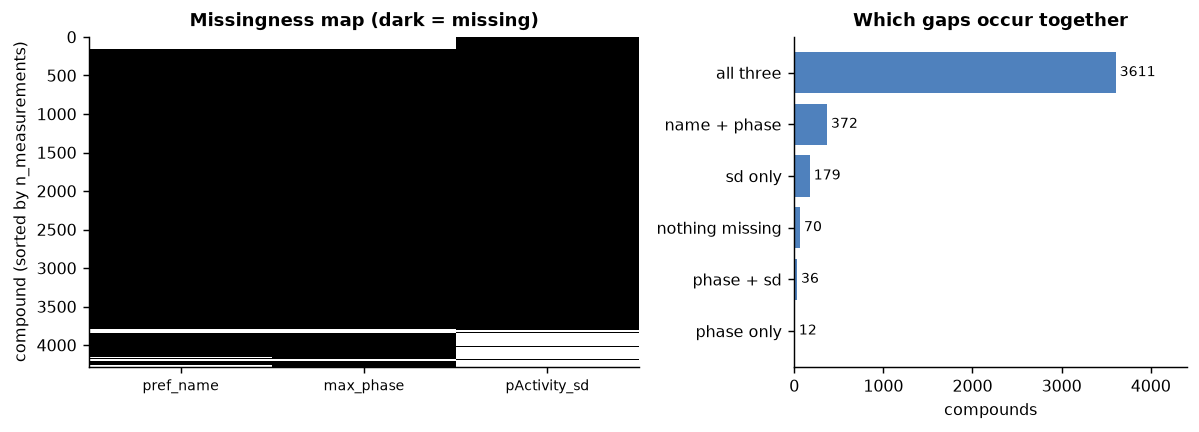

In [3]:
# A missingness map, and the co-occurrence of the gaps.
cols = [c for c in cmp.columns if cmp[c].isna().any()]
order = cmp.sort_values(["n_measurements", "max_phase"], na_position="last").index
fig, axes = plt.subplots(1, 2, figsize=(9.3, 3.4), width_ratios=[1.4, 1])
axes[0].imshow(cmp.loc[order, cols].isna().to_numpy(), aspect="auto",
               cmap="Greys", interpolation="nearest")
axes[0].set_xticks(range(len(cols))); axes[0].set_xticklabels(cols, rotation=0, fontsize=8)
axes[0].set_ylabel("compound (sorted by n_measurements)")
axes[0].set_title("Missingness map (dark = missing)")
combo = (cmp[cols].isna().astype(int).astype(str).agg("".join, axis=1).value_counts())
LAB = {"000": "nothing missing", "111": "all three", "110": "name + phase",
       "001": "sd only", "011": "phase + sd", "010": "phase only",
       "100": "name only", "101": "name + sd"}
axes[1].barh([LAB.get(k, k) for k in combo.index][::-1],
             combo.values[::-1], color="#4f81bd")
axes[1].set_xlabel("compounds"); axes[1].set_title("Which gaps occur together")
for i, v in enumerate(combo.values[::-1]):
    axes[1].text(v + 40, i, str(v), va="center", fontsize=7.5)
axes[1].set_xlim(0, combo.max() * 1.22)
plt.show()
print(combo.to_string())

<p class="caption"><b>Figure 1.</b> Left: the missingness map, rows sorted by number of measurements. The <code>pActivity_sd</code> column is dark for the lower block — the single-measurement compounds — and light above, a perfectly structured pattern. Right: the gap combinations. The dominant pattern is "name, phase and sd all missing" (3,611 compounds: unnamed molecules measured once), followed by "name and phase missing but sd present" (372). Only 70 compounds have no gap at all. Gaps that co-occur in a block like this are never random; each combination corresponds to a recognisable kind of compound, which is exactly the diagnosis Unit 4 called <em>structured</em> rather than MCAR missingness.</p>

In [4]:
# Checklist step 6, done before any plotting: impossible values, bounds, and two outlier rules.
bounds = {"pActivity": (2, 12), "MolWt": (50, 2000), "MolLogP": (-10, 12), "TPSA": (0, 500),
          "HBD": (0, 30), "HBA": (0, 40), "RotB": (0, 60), "QED": (0, 1), "FractionCSP3": (0, 1)}
viol = {c: int((~cmp[c].between(lo, hi)).sum()) for c, (lo, hi) in bounds.items()}
print("values outside physically possible bounds:", {k: v for k, v in viol.items() if v} or "none")

rep = []
for c in ["pActivity", "MolWt", "MolLogP", "TPSA", "RotB", "QED"]:
    v = cmp[c]
    z = (v - v.mean()) / v.std(ddof=1)
    q1, q3 = v.quantile([.25, .75]); iqr_c = q3 - q1
    rep.append(dict(column=c, n_z_gt_3=int((z.abs() > 3).sum()),
                    n_tukey=int(((v < q1 - 1.5 * iqr_c) | (v > q3 + 1.5 * iqr_c)).sum()),
                    min=v.min(), max=v.max()))
out = pd.DataFrame(rep).set_index("column").round(2)
print()
print(out.to_string())
h = cmp.loc[cmp["MolWt"].idxmax()]
print("\nheaviest compound: %.0f Da, %d heavy atoms, pActivity %.2f"
      % (h["MolWt"], h["HeavyAtoms"], h["pActivity"]))

values outside physically possible bounds: none

           n_z_gt_3  n_tukey     min     max
column                                      
pActivity         4        0    3.40    9.82
MolWt            20       36  133.15  990.22
MolLogP          14       66   -1.77    7.94
TPSA             19       43   12.89  382.54
RotB             20       35    0.00   20.00
QED               0        0    0.04    0.94

heaviest compound: 990 Da, 69 heavy atoms, pActivity 4.52


<p class="caption"><b>Table (Section 1, outliers).</b> No value violates a physical bound — a reassuring but necessary check, since a negative TPSA or a QED above 1 would mean a corrupt file rather than an unusual molecule. The two outlier rules disagree systematically: the z-score rule (|z| &gt; 3) flags far fewer points than Tukey's 1.5·IQR fence, because the standard deviation is itself inflated by the outliers it is meant to detect. Neither rule is a licence to delete. The heaviest compound here is 990 Da with 69 heavy atoms — twice the size of a typical drug, but a real peptide-like molecule, not an error.</p>

## 2. The grammar of graphics

Before plotting anything, it is worth having a vocabulary. Wilkinson's *grammar of graphics*, as refined by Wickham,<sup class="c"><a href="#r1">[1]</a></sup> says that any statistical graphic is built from independent layers:

- **Data** — the tidy table.
- **Aesthetic mapping** — which column drives which visual channel: position *x*, position *y*, colour, size, shape, transparency.
- **Geometry** — the mark that is drawn: point, line, bar, box, area.
- **Statistical transformation** — what is computed before drawing: identity, a count per bin, a density, a smoother.
- **Scales** — how data values become channel values: linear or logarithmic axis, a colour map, a size range.
- **Facets** — the rule that splits the data into small multiples.
- **Coordinates and theme** — the coordinate system and the non-data ink.

The value of the grammar is that it makes figure design a series of explicit choices rather than a search through a menu of chart types. "Histogram" is not a chart type; it is *geometry = bar, statistic = count per bin, x = the variable, y = the count*. Change the statistic to "density" and you have a density plot; change the geometry to "step" and you have a frequency polygon; add a facet and you have small multiples of all three.

In Python the grammar is not enforced by the library, so you must impose it yourself. Two levels of interface exist, and this course uses both deliberately. **matplotlib's object API** — `fig, ax = plt.subplots()` then `ax.something(...)` — gives complete control and is what every publication figure ends up being written in.<sup class="c"><a href="#r2">[2]</a></sup> **seaborn's figure-level functions** — `sns.displot`, `sns.relplot`, `sns.catplot` — take a tidy DataFrame and column *names*, and express mapping, statistic and faceting as keyword arguments, which is the grammar made concrete.<sup class="c"><a href="#r3">[3]</a></sup> Use seaborn to explore quickly; drop to matplotlib when the figure has to be exactly right. Both expect the table to be tidy in the sense of Unit 4<sup class="c"><a href="#r7">[7]</a></sup> — a column per variable — and the distinction between a figure made to think with and a figure made to publish is itself worth keeping explicit.<sup class="c"><a href="#r28">[28]</a></sup>

<cell 5>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
linear fit of pActivity on MolLogP: slope -0.025, r = -0.025, p = 0.184


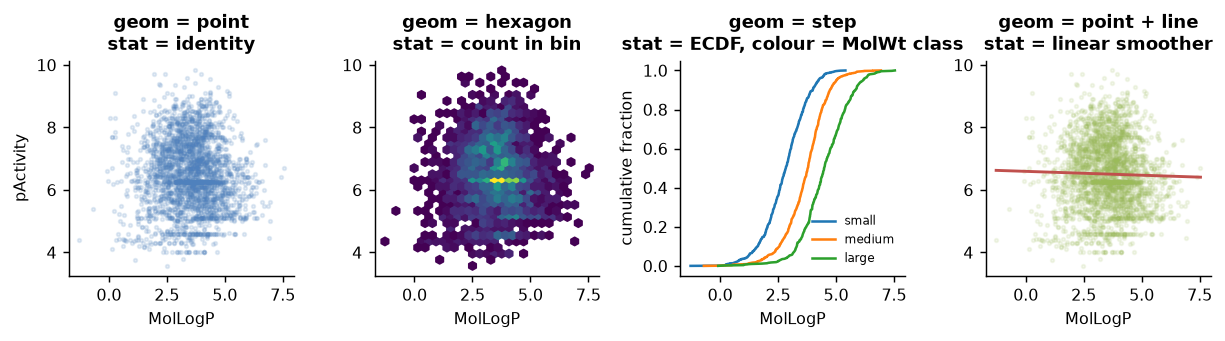

In [5]:
# The same data, the same geometry, four different layers changed: the grammar made visible.
d = cmp.loc[~cmp["censored"]].copy()
d["size_class"] = pd.cut(d["MolWt"], [0, 350, 450, 2000], labels=["small", "medium", "large"])
fig, axes = plt.subplots(1, 4, figsize=(9.5, 2.7), sharey=False)
axes[0].scatter(d["MolLogP"], d["pActivity"], s=4, alpha=.15, color="#4f81bd")
axes[0].set_title("geom = point\nstat = identity")
axes[1].hexbin(d["MolLogP"], d["pActivity"], gridsize=28, cmap="viridis", mincnt=1)
axes[1].set_title("geom = hexagon\nstat = count in bin")
for lab, sub in d.groupby("size_class", observed=True):
    axes[2].plot(np.sort(sub["MolLogP"]), np.linspace(0, 1, len(sub)), lw=1.4, label=str(lab))
axes[2].legend(fontsize=6.5, loc="lower right"); axes[2].set_ylabel("cumulative fraction")
axes[2].set_title("geom = step\nstat = ECDF, colour = MolWt class")
axes[3].scatter(d["MolLogP"], d["pActivity"], s=4, alpha=.12, color="#9bbb59")
sl = sstats.linregress(d["MolLogP"], d["pActivity"])
xs = np.linspace(d["MolLogP"].min(), d["MolLogP"].max(), 50)
axes[3].plot(xs, sl.intercept + sl.slope * xs, color="#c0504d", lw=1.6)
axes[3].set_title("geom = point + line\nstat = linear smoother")
for ax in axes:
    ax.set_xlabel("MolLogP")
axes[0].set_ylabel("pActivity")
plt.show()
print("linear fit of pActivity on MolLogP: slope %.3f, r = %.3f, p = %.3g"
      % (sl.slope, sl.rvalue, sl.pvalue))

<p class="caption"><b>Figure 2.</b> One dataset (the 2,764 compounds with exact measurements), four figures differing only in the grammar layers named in each title. The scatter shows every point but hides density; the hexbin shows density but hides individual points; the ECDF changes both the statistic and the aesthetic mapping (colour now encodes a molecular-weight class) and answers a different question — how the distributions of greasiness compare between size classes; the fourth adds a linear smoother. The fitted slope is −0.025 pActivity units per logP unit with r = −0.025 and p = 0.18 — no relation at all. Greasiness does not predict potency here, and the regression line exists only to make that visible.</p>

<cell 6>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
                                       n  median
replicated         measured                     
replicated         censored only     117    5.00
                   has exact value   375    6.78
single measurement censored only    1399    5.00
                   has exact value  2389    6.40

censored fraction: single-measurement 37%, replicated 24%


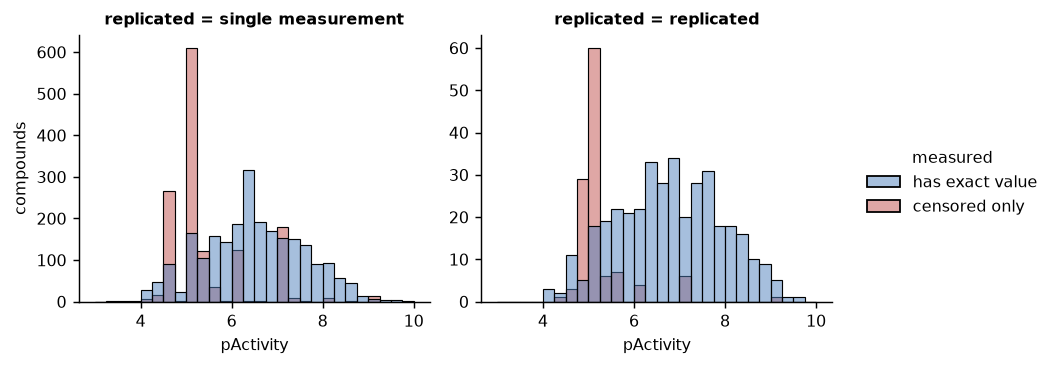

In [6]:
# The same grammar expressed by seaborn's figure-level interface: mapping, statistic and facet as keywords.
plot_df = cmp.assign(measured=np.where(cmp["censored"], "censored only", "has exact value"),
                     replicated=np.where(cmp["n_measurements"] > 1, "replicated", "single measurement"))
g = sns.displot(data=plot_df, x="pActivity", hue="measured", col="replicated",
                kind="hist", bins=np.arange(3.0, 10.1, 0.25), height=2.9, aspect=1.15,
                palette={"has exact value": "#4f81bd", "censored only": "#c0504d"},
                facet_kws=dict(sharey=False))
g.set_axis_labels("pActivity", "compounds")
plt.show()
tab = (plot_df.groupby(["replicated", "measured"], observed=True)["pActivity"]
              .agg(n="size", median="median").round(2))
print(tab.to_string())
print("\ncensored fraction: single-measurement %.0f%%, replicated %.0f%%"
      % (100 * plot_df.loc[plot_df["replicated"] == "single measurement", "censored"].mean(),
         100 * plot_df.loc[plot_df["replicated"] == "replicated", "censored"].mean()))

<p class="caption"><b>Figure 3.</b> The same table through seaborn's figure-level <code>displot</code>: one call declares the aesthetic mapping (<code>x</code>, <code>hue</code>), the statistic (<code>kind="hist"</code>), the facet (<code>col</code>) and the scales. Compounds measured once (left panel) and more than once (right) have visibly different compositions — 37% of the 3,788 single-measurement compounds are censored-only against 24% of the 492 replicated ones, because a compound worth measuring twice was usually worth measuring at all. That is the grammar's payoff: the question "does the censoring rate depend on replication?" became two keyword arguments.</p>

## 3. Distributions: histogram, KDE, ECDF — and what each hides

The histogram is the first plot anyone draws and the one with the largest hidden parameter: the **bin width**. Two standard rules exist. Scott's rule<sup class="c"><a href="#r12">[12]</a></sup> chooses *h* = 3.49 σ n<sup>−1/3</sup>, optimal for data that are roughly normal; the Freedman–Diaconis rule<sup class="c"><a href="#r13">[13]</a></sup> uses *h* = 2·IQR·n<sup>−1/3</sup>, which is robust to outliers because the interquartile range is. Neither is right for multimodal data, where the bin width that reveals the modes is a judgement.<sup class="c"><a href="#r14">[14]</a></sup> The honest practice is to look at several and say which one you are showing.

n = 2764; Scott bin width = 0.276; Freedman-Diaconis = 0.224 log units
<cell 7>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


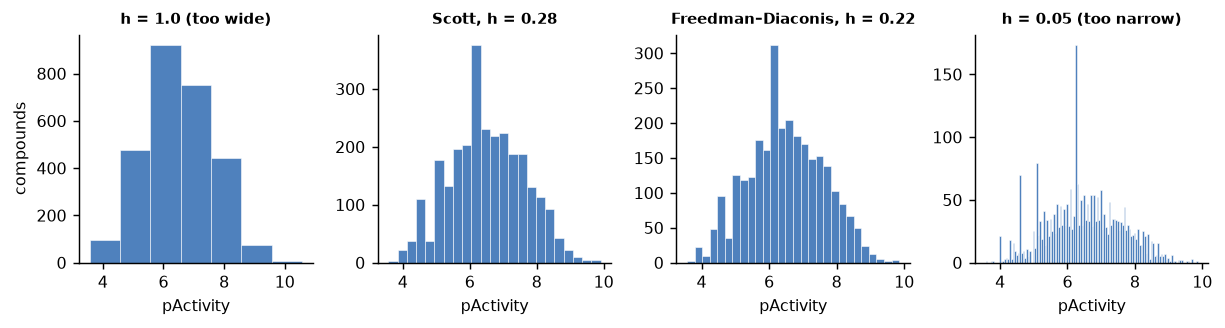

In [7]:
# The same 2,764 values, four bin widths. The bin width is a parameter, not a detail.
y = d["pActivity"].to_numpy()
n = len(y)
h_scott = 3.49 * y.std(ddof=1) * n ** (-1 / 3)
iqr = np.subtract(*np.percentile(y, [75, 25]))
h_fd = 2 * iqr * n ** (-1 / 3)
print(f"n = {n}; Scott bin width = {h_scott:.3f}; Freedman-Diaconis = {h_fd:.3f} log units")

fig, axes = plt.subplots(1, 4, figsize=(9.5, 2.6), sharey=False)
for ax, h, ttl in zip(axes, [1.0, h_scott, h_fd, 0.05],
                      ["h = 1.0 (too wide)", f"Scott, h = {h_scott:.2f}",
                       f"Freedman–Diaconis, h = {h_fd:.2f}", "h = 0.05 (too narrow)"]):
    bins = np.arange(y.min(), y.max() + h, h)
    ax.hist(y, bins=bins, color="#4f81bd", edgecolor="white", linewidth=.3)
    ax.set_title(ttl, fontsize=8.5); ax.set_xlabel("pActivity")
axes[0].set_ylabel("compounds")
plt.show()

<p class="caption"><b>Figure 4.</b> The potency distribution of the same 2,764 compounds at four bin widths. At h = 1.0 the distribution looks like a smooth single hump. At the Scott and Freedman–Diaconis widths (0.28 and 0.22 log units) a broad, slightly right-skewed unimodal shape is visible (Fisher skewness +0.06; mean 6.51 above median 6.44). At h = 0.05 the histogram dissolves into spikes — but those spikes are not noise: the tallest of them, near pActivity 6.26, is a real pile-up of 141 compounds reported with identical potency, which Section 9 traces to its source. A bin width too small is usually useless; here it was the first clue to an anomaly.</p>

Three displays answer the "what is the distribution?" question, and they fail in different ways. The **histogram** depends on bin width *and* bin origin. The **kernel density estimate** replaces bins with a smooth kernel and depends on a bandwidth; it also smooths across hard boundaries, inventing density where none can exist. The **empirical cumulative distribution function** has no free parameter at all: it plots, for every observed value, the fraction of observations at or below it. The ECDF is the only one of the three that shows the data exactly, and the only one most readers cannot read fluently — which is the trade.

<cell 8>:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
quartiles of pActivity (exact compounds): 5.73 / 6.44 / 7.30
fraction of censored-only compounds at exactly pActivity 5.00: 42%


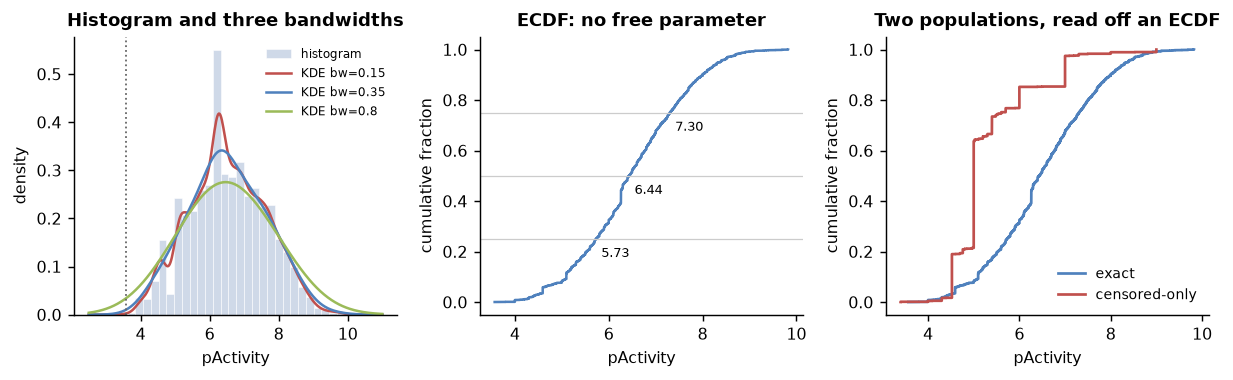

In [8]:
# Histogram vs KDE vs ECDF on the same values, plus the KDE's boundary artefact.
fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.0))
axes[0].hist(y, bins=np.arange(3.4, 10.1, h_fd), density=True, color="#cfd9e8",
             edgecolor="white", linewidth=.3, label="histogram")
for bw, col in [(0.15, "#c0504d"), (0.35, "#4f81bd"), (0.8, "#9bbb59")]:
    kde = sstats.gaussian_kde(y, bw_method=bw)
    xs = np.linspace(2.5, 11, 400)
    axes[0].plot(xs, kde(xs), color=col, lw=1.4, label=f"KDE bw={bw}")
axes[0].axvline(y.min(), color="0.4", ls=":", lw=1)
axes[0].set_xlabel("pActivity"); axes[0].set_ylabel("density")
axes[0].set_title("Histogram and three bandwidths"); axes[0].legend(fontsize=6.8)

xs = np.sort(y)
axes[1].step(xs, np.arange(1, n + 1) / n, where="post", color="#4f81bd", lw=1.4)
for q in (.25, .5, .75):
    axes[1].axhline(q, color="0.8", lw=.7)
    axes[1].annotate(f"{np.quantile(y, q):.2f}", (np.quantile(y, q), q), fontsize=7,
                     xytext=(3, -10), textcoords="offset points")
axes[1].set_xlabel("pActivity"); axes[1].set_ylabel("cumulative fraction")
axes[1].set_title("ECDF: no free parameter")

for lab, sub, col in [("exact", cmp.loc[~cmp["censored"], "pActivity"], "#4f81bd"),
                      ("censored-only", cmp.loc[cmp["censored"], "pActivity"], "#c0504d")]:
    v = np.sort(sub.to_numpy())
    axes[2].step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=col, lw=1.5, label=lab)
axes[2].set_xlabel("pActivity"); axes[2].set_ylabel("cumulative fraction")
axes[2].set_title("Two populations, read off an ECDF"); axes[2].legend(fontsize=7.5)
plt.show()
print("quartiles of pActivity (exact compounds): %.2f / %.2f / %.2f"
      % tuple(np.quantile(y, [.25, .5, .75])))
print("fraction of censored-only compounds at exactly pActivity 5.00: %.0f%%"
      % (100 * np.isclose(cmp.loc[cmp['censored'], 'pActivity'], 5.0).mean()))

<p class="caption"><b>Figure 5.</b> Left: the histogram with three KDE bandwidths over it. At bw = 0.15 the density is lumpy and over-fits; at 0.8 it is a featureless hump. All three extend past the dotted line marking the smallest observed value, assigning density to potencies that were never measured — the boundary artefact that makes a KDE the wrong choice for bounded data unless the boundary is handled explicitly. Middle: the ECDF of the same values, with the quartiles (5.73, 6.44, 7.30) read directly off the curve; it has no tuning parameter and no artefact. Right: the ECDF makes the two populations in this dataset immediately comparable — the censored-only compounds (red) rise almost vertically at pActivity 5.00, because 42% of them sit exactly there, the "&gt; 10 µM" screening limit. A histogram of the pooled data would show this as a mysterious spike; the ECDF shows it as what it is, a point mass.</p>

## 4. Comparing groups: box, violin, strip — and how each misleads

Checklist item 5 asks whether the variable of interest differs between groups. In this dataset the natural grouping is the **scaffold family**: compounds sharing a Bemis–Murcko scaffold are chemical relatives, usually from the same paper and the same optimisation campaign.

The box plot<sup class="c"><a href="#r16">[16]</a></sup> summarises each group with five numbers and is unbeatable for comparing many groups at once. It also hides everything that is not those five numbers: the sample size, multimodality, and gaps. The violin plot<sup class="c"><a href="#r15">[15]</a></sup> shows a mirrored KDE and therefore inherits the bandwidth and boundary problems of Section 3. The strip (or jitter) plot shows every point and fails only when there are too many. Nature Methods and the biomedical literature have been arguing for a decade that bar charts and box plots should be replaced by, or at least combined with, the raw points,<sup class="c"><a href="#r17">[17]</a></sup><sup class="c"><a href="#r18">[18]</a></sup><sup class="c"><a href="#r19">[19]</a></sup><sup class="c"><a href="#r20">[20]</a></sup> and the "raincloud" combination of half-violin, box and points is the current consensus display.<sup class="c"><a href="#r21">[21]</a></sup>

<cell 9>:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
          n  median    sd    lo    hi
family                               
S1      207    7.52  0.81  5.39  9.70
S2       23    5.10  0.19  4.65  5.10
S3       59    6.23  1.00  4.28  8.05
S4       43    7.02  0.95  4.80  9.10
S5       38    6.87  0.48  5.64  7.62
S6       16    6.26  0.80  4.59  6.26


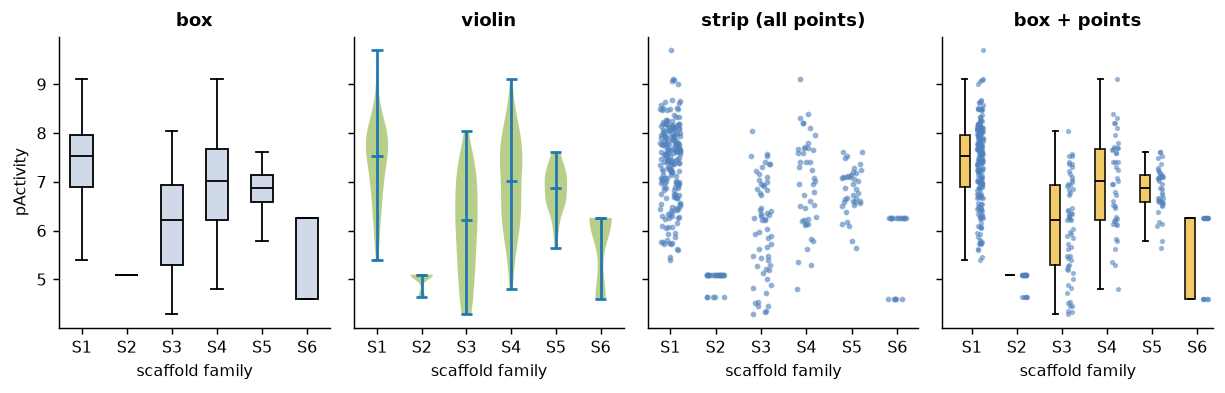

In [9]:
# Four displays of the same six scaffold families, in increasing order of honesty.
top6 = cmp["scaffold_smiles"].value_counts().head(6).index.tolist()
fam = d[d["scaffold_smiles"].isin(top6)].copy()
fam["family"] = fam["scaffold_smiles"].map({s: f"S{i+1}" for i, s in enumerate(top6)})
order = sorted(fam["family"].unique())
groups = [fam.loc[fam["family"] == g, "pActivity"].to_numpy() for g in order]

fig, axes = plt.subplots(1, 4, figsize=(9.5, 3.1), sharey=True)
axes[0].boxplot(groups, tick_labels=order, showfliers=False, patch_artist=True,
                boxprops=dict(facecolor="#cfd9e8"), medianprops=dict(color="black"))
axes[0].set_title("box")
parts = axes[1].violinplot(groups, showmedians=True)
for b in parts["bodies"]:
    b.set_facecolor("#9bbb59"); b.set_alpha(.7)
axes[1].set_xticks(range(1, 7)); axes[1].set_xticklabels(order); axes[1].set_title("violin")
rng = np.random.default_rng(0)
for i, g in enumerate(groups, start=1):
    axes[2].scatter(i + rng.uniform(-.22, .22, len(g)), g, s=5, alpha=.5, color="#4f81bd")
axes[2].set_xticks(range(1, 7)); axes[2].set_xticklabels(order); axes[2].set_title("strip (all points)")
for i, g in enumerate(groups, start=1):
    axes[3].scatter(i + 0.18 + rng.uniform(-.07, .07, len(g)), g, s=4, alpha=.45, color="#4f81bd")
    bp = axes[3].boxplot([g], positions=[i - 0.15], widths=.22, showfliers=False, patch_artist=True,
                         boxprops=dict(facecolor="#f2c14e", alpha=.85), medianprops=dict(color="black"))
axes[3].set_xticks(range(1, 7)); axes[3].set_xticklabels(order); axes[3].set_title("box + points")
axes[0].set_ylabel("pActivity")
for ax in axes:
    ax.set_xlabel("scaffold family")
plt.show()
print(fam.groupby("family", observed=True)["pActivity"]
         .agg(n="size", median="median", sd="std", lo="min", hi="max").round(2).to_string())

<p class="caption"><b>Figure 6.</b> Six scaffold families, four displays. The box plot (left) makes the comparison instantly: family S1 (median 7.52) is more than a log unit above S3 (6.23) and almost two and a half above S2 (5.10). What it does not show is that S1 contains 207 compounds and S6 only 16 — boxes of equal width standing for samples that differ thirteenfold in size. The violin adds shape but smooths S2 into a symmetric blob, when in fact all 23 of its compounds lie between 4.65 and 5.10 with a hard ceiling at 5.10, and it does the same to S6, whose 16 compounds end at exactly 6.26. Only the strip and the box-with-points show both: the family sizes, and the fact that S2 and S6 are walls of points against a limit rather than distributions. Always draw the points when the group has fewer than a few hundred members.</p>

The strongest demonstration is a constructed one: two samples with *identical* box plots and completely different distributions.

        unimodal  bimodal
min         3.82     4.83
Q1          5.75     5.77
median      6.35     6.28
Q3          6.91     6.83
max         9.35     7.73
<cell 10>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
excess kurtosis: A = 0.44, B = -1.13 (a strongly negative value flags bimodality)


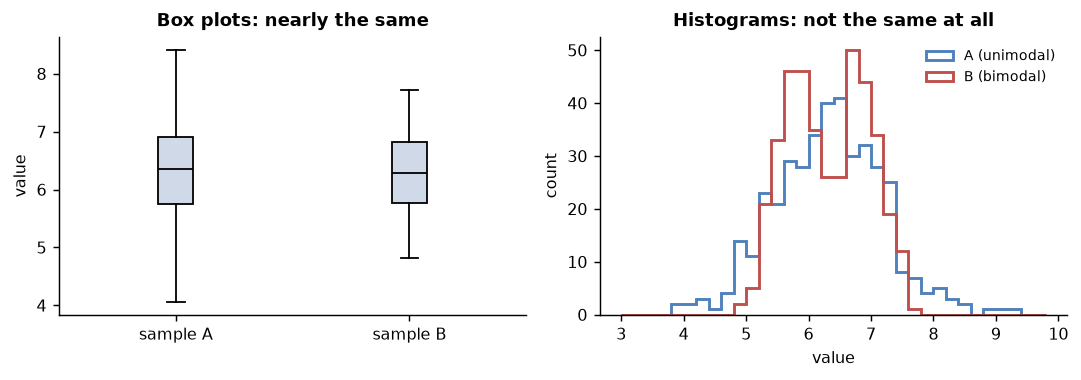

In [10]:
# Two samples whose box plots are nearly identical and whose distributions are not.
rng = np.random.default_rng(1)
m = 400
uni = rng.normal(6.4, 0.95, m)
# A two-component mixture whose quartiles match by construction: for an equal mixture the median is
# the midpoint of the two means and the quartiles are the component medians themselves.
q1, med, q3 = np.percentile(uni, [25, 50, 75])
bim = np.concatenate([rng.normal(q1, 0.30, m // 2), rng.normal(q3, 0.30, m // 2)])
summ = pd.DataFrame({"unimodal": np.percentile(uni, [0, 25, 50, 75, 100]),
                     "bimodal": np.percentile(bim, [0, 25, 50, 75, 100])},
                    index=["min", "Q1", "median", "Q3", "max"]).round(2)
print(summ.to_string())
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.0))
axes[0].boxplot([uni, bim], tick_labels=["sample A", "sample B"], showfliers=False,
                patch_artist=True, boxprops=dict(facecolor="#cfd9e8"), medianprops=dict(color="black"))
axes[0].set_ylabel("value"); axes[0].set_title("Box plots: nearly the same")
for v, lab, col in [(uni, "A (unimodal)", "#4f81bd"), (bim, "B (bimodal)", "#c0504d")]:
    axes[1].hist(v, bins=np.arange(3, 10, .2), histtype="step", lw=1.6, color=col, label=lab)
axes[1].set_xlabel("value"); axes[1].set_ylabel("count"); axes[1].legend(fontsize=7.5)
axes[1].set_title("Histograms: not the same at all")
plt.show()
dip_u = sstats.kurtosis(uni); dip_b = sstats.kurtosis(bim)
print("excess kurtosis: A = %.2f, B = %.2f (a strongly negative value flags bimodality)" % (dip_u, dip_b))

<p class="caption"><b>Figure 7.</b> Two samples of 400 values with almost identical quartiles and therefore almost identical box plots, but entirely different shapes: A is a single hump, B is two separated clusters. No five-number summary can tell them apart, and no statistical test applied to the medians would notice. The excess kurtosis (+0.44 against −1.13) does flag the difference, but only because we thought to compute it. The general lesson: a box plot answers "where is the middle and how wide is the spread", and nothing else.</p>

<div class="exercise"><h4>Exercise 1</h4>
<p>Replace the box plots in Figure 6 by violins with <code>bw_method=0.2</code> and again with <code>bw_method=1.0</code>. Which families change appearance most, and why are they the small ones? Then plot family S2 alone as an ECDF and state in one sentence what the violin was hiding.</p></div>

In [11]:
# Is the pooled potency distribution bimodal? A coefficient, and why the answer depends on censoring.
def bimodality_coefficient(v):
    '''Sarle's b = (g1^2 + 1) / (g2 + 3(n-1)^2/((n-2)(n-3))); b > 5/9 is the usual reference value.'''
    v = np.asarray(v, float); nn = len(v)
    g1 = sstats.skew(v, bias=False); g2 = sstats.kurtosis(v, bias=False)
    return (g1 ** 2 + 1) / (g2 + 3 * (nn - 1) ** 2 / ((nn - 2) * (nn - 3)))

for name, v in [("exact compounds only", cmp.loc[~cmp["censored"], "pActivity"]),
                ("all compounds (pooled)", cmp["pActivity"]),
                ("constructed bimodal sample B", bim)]:
    b = bimodality_coefficient(v)
    print(f"{name:<30s} n={len(v):<5d} b = {b:.3f}   {'-> bimodal' if b > 5/9 else ''}")
print("\ncompounds sitting at exactly pActivity 5.00: %d (%.1f%% of the pooled set)"
      % (int(np.isclose(cmp['pActivity'], 5.0).sum()), 100 * np.isclose(cmp['pActivity'], 5.0).mean()))

exact compounds only           n=2764  b = 0.391   
all compounds (pooled)         n=4280  b = 0.500   
constructed bimodal sample B   n=400   b = 0.528   

compounds sitting at exactly pActivity 5.00: 658 (15.4% of the pooled set)


Read the three numbers carefully, because they make two points at once. Sarle's coefficient does order the samples correctly — 0.391 for the exact compounds, 0.500 for the pooled set, 0.528 for the constructed mixture of Figure 7 — so pooling the censored compounds does move the distribution towards bimodality. But <em>none</em> of the three crosses the usual 5/9 ≈ 0.556 reference value, including the sample we built to be bimodal and can see is bimodal. A one-number test for shape is weak, which is why Hartigan's dip test exists as the formal tool<sup class="c"><a href="#r22">[22]</a></sup> and why neither is a substitute for the plot. The real diagnosis is mechanistic: the second mode of the pooled distribution is the 658 compounds sitting at exactly pActivity 5.00, the "&gt; 10 µM" screening limit, so the apparent bimodality of "the ROCK1 potency distribution" is a property of the experiments, not of the chemistry.

## 5. Relationships and the overplotting problem

Checklist item 4 is the pairwise structure. A scatter plot of 4,280 points is already past the density at which a scatter plot works: the ink saturates, and the eye reads the *outline* of the cloud rather than its density. Three standard repairs exist — transparency, binning (hexbin or 2-D histogram), and subsampling — and each trades something different.

<cell 12>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
points: 4280 | densest hexbin cell holds 79 compounds
Pearson r(MolWt, MolLogP) = 0.608 | Spearman = 0.617


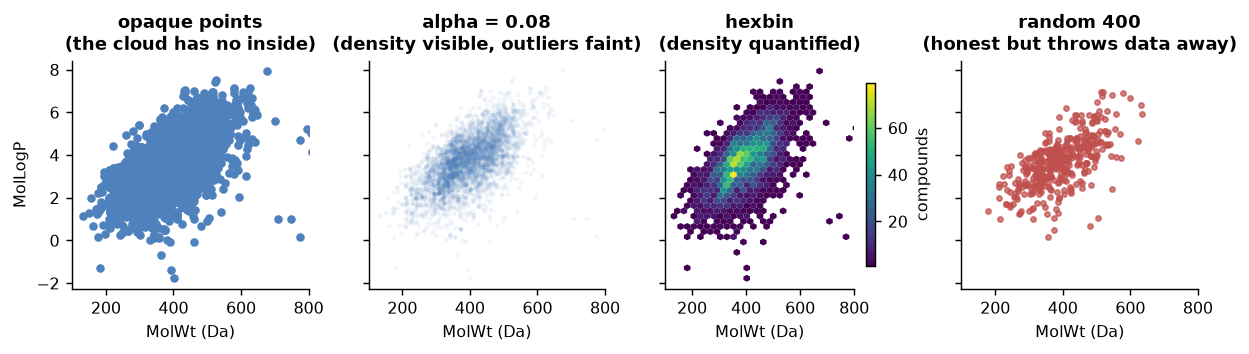

In [12]:
# The same 4,280 compounds, four treatments of overplotting.
x, yv = cmp["MolWt"].to_numpy(), cmp["MolLogP"].to_numpy()
fig, axes = plt.subplots(1, 4, figsize=(9.5, 2.8), sharex=True, sharey=True)
axes[0].scatter(x, yv, s=14, color="#4f81bd")
axes[0].set_title("opaque points\n(the cloud has no inside)")
axes[1].scatter(x, yv, s=6, alpha=.08, color="#4f81bd", edgecolor="none")
axes[1].set_title("alpha = 0.08\n(density visible, outliers faint)")
hb = axes[2].hexbin(x, yv, gridsize=35, cmap="viridis", mincnt=1, linewidths=0)
axes[2].set_title("hexbin\n(density quantified)")
fig.colorbar(hb, ax=axes[2], shrink=.8, label="compounds")
sub = cmp.sample(400, random_state=0)
axes[3].scatter(sub["MolWt"], sub["MolLogP"], s=8, alpha=.7, color="#c0504d")
axes[3].set_title("random 400\n(honest but throws data away)")
for ax in axes:
    ax.set_xlabel("MolWt (Da)")
axes[0].set_ylabel("MolLogP"); axes[0].set_xlim(100, 800)
plt.show()
print("points:", len(cmp), "| densest hexbin cell holds", int(hb.get_array().max()), "compounds")
print("Pearson r(MolWt, MolLogP) = %.3f | Spearman = %.3f"
      % (cmp["MolWt"].corr(cmp["MolLogP"]), cmp["MolWt"].corr(cmp["MolLogP"], method="spearman")))

<p class="caption"><b>Figure 8.</b> Four views of molecular weight against lipophilicity for all 4,280 compounds. The opaque scatter is a silhouette: it shows the support of the distribution and nothing about where the mass is. Transparency recovers the density but makes isolated compounds — the interesting ones — nearly invisible. The hexbin quantifies the density, with the busiest cell holding 79 compounds, but it discards the individual points entirely and introduces its own bin-size parameter. The 400-point subsample is readable and honest if the caption says so. In practice: transparency plus a separate marked layer for the points you want seen, or hexbin plus a note of the maximum cell count.</p>

The correlation between weight and lipophilicity here is 0.61 (Pearson, 0.62 Spearman) — a real but loose relation of the kind a scatter plot communicates far better than a single number.

<div class="box bridge"><h4>Domain context — what a medicinal chemist looks at first</h4>
<p>Faced with a new activity dataset, a medicinal chemist looks for three things. First, the <strong>potency distribution</strong>: how many compounds are genuinely potent (pActivity above about 7, i.e. below 100 nM) and how many are at the screening floor. Second, the <strong>property distributions</strong> against the ranges associated with orally absorbed drugs — Lipinski's rule of five, which observes that most oral drugs have molecular weight below 500, logP below 5, at most 5 hydrogen-bond donors and at most 10 acceptors.<sup class="c"><a href="#r31">[31]</a></sup> Third, <strong>activity cliffs</strong>: pairs of nearly identical molecules with very different potencies, which are both the most informative compounds in a series and the ones that break similarity-based models.<sup class="c"><a href="#r33">[33]</a></sup><sup class="c"><a href="#r34">[34]</a></sup></p></div>

## 6. Correlation structure

Checklist item 4 again, now for every pair at once. Two cautions before drawing a correlation matrix. **Pearson's** coefficient measures linear association and is sensitive to outliers; **Spearman's** measures monotone association by correlating ranks and is not. Report which you used. And remember that a correlation matrix shows only pairwise relations: variables can be strongly dependent with zero correlation.

<cell 13>:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
strongest descriptor pairs (Pearson):
MolWt          HeavyAtoms       0.979
HeavyAtoms     QED              0.807
MolWt          QED              0.803
QED            AromaticRings    0.755
AromaticRings  RingCount        0.714

correlation of each descriptor with pActivity:
               pearson  spearman
AromaticRings   -0.101    -0.121
RingCount       -0.079    -0.107
HBA             -0.045    -0.087
MolLogP         -0.025    -0.055
TPSA             0.025    -0.006
QED              0.025     0.050
HBD              0.075     0.085
MolWt            0.077     0.016
HeavyAtoms       0.080     0.022
FractionCSP3     0.114     0.145
RotB             0.241     0.226


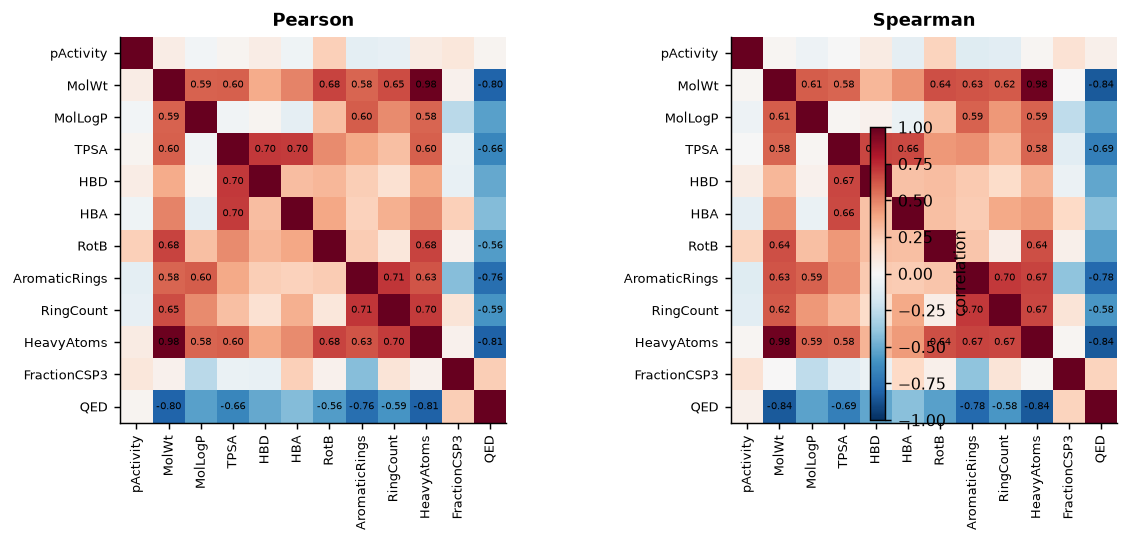

In [13]:
# Descriptor correlation: Pearson, Spearman, and the clustered version that reveals blocks.
feat = ["pActivity", "MolWt", "MolLogP", "TPSA", "HBD", "HBA", "RotB",
        "AromaticRings", "RingCount", "HeavyAtoms", "FractionCSP3", "QED"]
P = d[feat].corr(); S = d[feat].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
for ax, M, ttl in [(axes[0], P, "Pearson"), (axes[1], S, "Spearman")]:
    im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(feat))); ax.set_xticklabels(feat, rotation=90, fontsize=7)
    ax.set_yticks(range(len(feat))); ax.set_yticklabels(feat, fontsize=7)
    ax.set_title(ttl)
    for i in range(len(feat)):
        for j in range(len(feat)):
            if abs(M.iloc[i, j]) > .55 and i != j:
                ax.text(j, i, f"{M.iloc[i, j]:.2f}", ha="center", va="center", fontsize=5.6)
fig.colorbar(im, ax=axes, shrink=.75, label="correlation")
plt.show()
mask = ~np.eye(len(feat), dtype=bool)
pairs = P.where(mask).abs().stack().sort_values(ascending=False)
print("strongest descriptor pairs (Pearson):")
print(pairs.iloc[::2].head(5).round(3).to_string())
print("\ncorrelation of each descriptor with pActivity:")
print(pd.DataFrame({"pearson": P["pActivity"], "spearman": S["pActivity"]})
      .drop("pActivity").round(3).sort_values("pearson").to_string())

<p class="caption"><b>Figure 9.</b> Pearson and Spearman correlation matrices of eleven descriptors plus the target. The two are visually almost identical here, which is itself the finding: the relations are monotone and not driven by outliers. The dark-red block in the lower right is the size family — <code>MolWt</code> and <code>HeavyAtoms</code> correlate at 0.979, so they carry one piece of information between them, and <code>QED</code> is strongly anti-correlated with both (−0.80) because its definition penalises large molecules. The target row is almost white: the strongest correlation of any descriptor with potency is <code>RotB</code> at 0.241, and everything else is below 0.12. Simple descriptors do not predict ROCK1 potency — which is precisely why Units 11–17 use structural fingerprints instead.</p>

A **clustermap** reorders rows and columns by hierarchical clustering so that correlated blocks become contiguous. On twelve variables the gain is modest; on a hundred it is the difference between a readable figure and a grey square.

<cell 14>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
column order after clustering: ['QED', 'HBA', 'TPSA', 'HBD', 'RotB', 'MolWt', 'HeavyAtoms', 'MolLogP', 'AromaticRings', 'RingCount', 'pActivity', 'FractionCSP3']


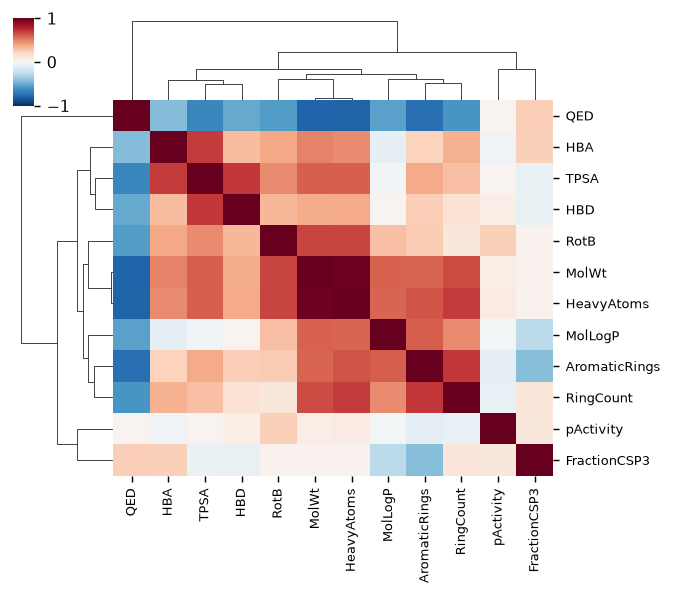

In [14]:
# Clustermap: the same matrix with rows and columns reordered by hierarchical clustering.
g = sns.clustermap(P, cmap="RdBu_r", vmin=-1, vmax=1, figsize=(5.4, 4.8),
                   annot=False, cbar_pos=(0.02, 0.83, 0.03, 0.14),
                   dendrogram_ratio=(.18, .18))
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=7, rotation=90)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=7, rotation=0)
plt.show()
print("column order after clustering:", [feat[i] for i in g.dendrogram_col.reordered_ind])

<p class="caption"><b>Figure 10.</b> The same correlation matrix as a clustermap. The reordering brings the recognisable families together: <code>MolWt</code> beside <code>HeavyAtoms</code>, the polarity group <code>HBA</code>/<code>TPSA</code>/<code>HBD</code>, and <code>MolLogP</code> beside <code>AromaticRings</code> and <code>RingCount</code>. <code>pActivity</code> lands between <code>RingCount</code> and <code>FractionCSP3</code> — not because it is related to either, but because a variable correlated with nothing has no natural neighbour and the algorithm must still place it somewhere. That is the main caution about dendrograms: every leaf gets a position whether or not it has a reason to be there, and the branch order depends on the linkage and distance chosen.</p>

<p class="caption">The printed column order confirms it: <code>QED</code>, <code>HBA</code>, <code>TPSA</code>, <code>HBD</code>, <code>RotB</code>, <code>MolWt</code>, <code>HeavyAtoms</code>, <code>MolLogP</code>, <code>AromaticRings</code>, <code>RingCount</code>, <code>pActivity</code>, <code>FractionCSP3</code>.</p>

## 7. Small multiples and scales

Faceting — Tufte's *small multiples* — answers "does this relation hold in every subgroup?" by repeating one small plot across the levels of a variable, with shared axes so the panels are comparable. Shared axes are the whole point; panels with independent axes are four unrelated figures in a grid.

The other decision is the **scale**. Potency data are log-normal-ish over six orders of magnitude, which is why the field works in pActivity at all; plotting raw nanomolar concentrations on a linear axis compresses 99% of the compounds into the leftmost pixel column.

<cell 15>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
fraction of compounds below one-thirtieth of the largest IC50: 91.2%
median potency by class:
                  n  median_MolWt
potency_class                    
weak (<5.5)    1667         405.4
moderate       1075         393.4
good            961         385.5
potent (>7.5)   577         370.9


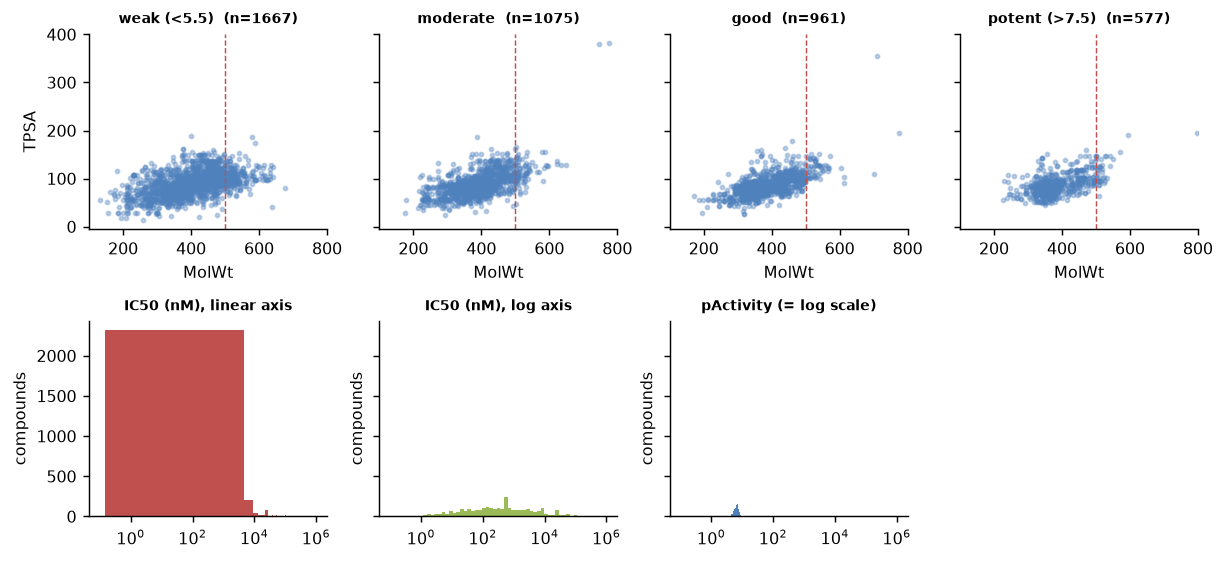

In [15]:
# Small multiples with shared axes, and the same data on linear and logarithmic concentration scales.
cmp["potency_class"] = pd.cut(cmp["pActivity"], [0, 5.5, 6.5, 7.5, 12],
                              labels=["weak (<5.5)", "moderate", "good", "potent (>7.5)"])
fig, axes = plt.subplots(2, 4, figsize=(9.5, 4.4), sharex="row", sharey="row")
for ax, (lab, sub) in zip(axes[0], cmp.groupby("potency_class", observed=True)):
    ax.scatter(sub["MolWt"], sub["TPSA"], s=5, alpha=.35, color="#4f81bd")
    ax.set_title(f"{lab}  (n={len(sub)})", fontsize=8)
    ax.set_xlabel("MolWt"); ax.axvline(500, color="#c0504d", lw=.8, ls="--")
axes[0][0].set_ylabel("TPSA"); axes[0][0].set_xlim(100, 800)

ic50_nM = 10 ** (9 - d["pActivity"])
axes[1][0].hist(ic50_nM, bins=60, color="#c0504d"); axes[1][0].set_title("IC50 (nM), linear axis", fontsize=8)
axes[1][1].hist(ic50_nM, bins=np.logspace(-1, 6, 60), color="#9bbb59")
axes[1][1].set_xscale("log"); axes[1][1].set_title("IC50 (nM), log axis", fontsize=8)
axes[1][2].hist(d["pActivity"], bins=40, color="#4f81bd"); axes[1][2].set_title("pActivity (= log scale)", fontsize=8)
axes[1][3].axis("off")
axes[1][3].text(0, .5, "Same 2,764 numbers.\nOn a linear concentration axis\n97% of them fall in the\nfirst two bins; the logarithmic\nand pActivity views are the\nsame picture, reflected.",
                fontsize=7.6, va="center")
for ax in axes[1][:3]:
    ax.set_ylabel("compounds")
plt.show()
print("fraction of compounds below one-thirtieth of the largest IC50: %.1f%%"
      % (100 * (ic50_nM < ic50_nM.max() / 30).mean()))
print("median potency by class:")
print(cmp.groupby("potency_class", observed=True)["MolWt"].agg(n="size", median_MolWt="median").round(1).to_string())

<p class="caption"><b>Figure 11.</b> Top row: four small multiples of polar surface area against molecular weight, one per potency class, with shared axes and Lipinski's 500-dalton line marked. The clouds are nearly indistinguishable — potent and weak compounds occupy the same property space, consistent with the near-zero correlations of Figure 9; the only systematic movement is a mild decline in median molecular weight, from 405 Da in the weak class (n = 1,667) to 371 Da in the potent one (n = 577). Bottom row: the same 2,764 potencies as raw nanomolar concentrations on a linear axis (useless: 91% of compounds fall below one-thirtieth of the largest value, so the axis is dominated by a handful of millimolar outliers), on a logarithmic axis, and as pActivity. The last two are the same picture reflected, which is why the field reports the logarithm.</p>

## 8. Same statistics, different graphs

Anscombe published four small datasets in 1973 with identical means, variances, correlation and regression line, and four completely different scatter plots.<sup class="c"><a href="#r9">[9]</a></sup> The point was not a curiosity; it was an argument that numerical summaries are insufficient and that looking is a required step.

<h4>Worked example by hand</h4>

Take Anscombe's set I: *x* = 10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5. Their sum is 99, so the mean is 99/11 = **9.00**. The deviations from the mean are 1, −1, 4, 0, 2, 5, −3, −5, 3, −2, −4; their squares sum to 1+1+16+0+4+25+9+25+9+4+16 = **110**, so the sample variance is 110/10 = **11.00** and the standard deviation √11 = 3.3166. Set II has exactly the same *x* values, so these three numbers are identical by construction; sets I–III share the *x* column entirely, and set IV has a different one chosen to give the same mean and variance. The cell below confirms all of this to two decimals and draws the four pictures.

set  mean_x  var_x  mean_y  var_y  corr  slope  intercept
  I     9.0   11.0     7.5   4.13  0.82    0.5        3.0
 II     9.0   11.0     7.5   4.13  0.82    0.5        3.0
III     9.0   11.0     7.5   4.12  0.82    0.5        3.0
 IV     9.0   11.0     7.5   4.12  0.82    0.5        3.0

hand check of set I: mean_x = 99/11 = 9.00, var_x = 110/10 = 11.00, sd = 3.3166
<cell 16>:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


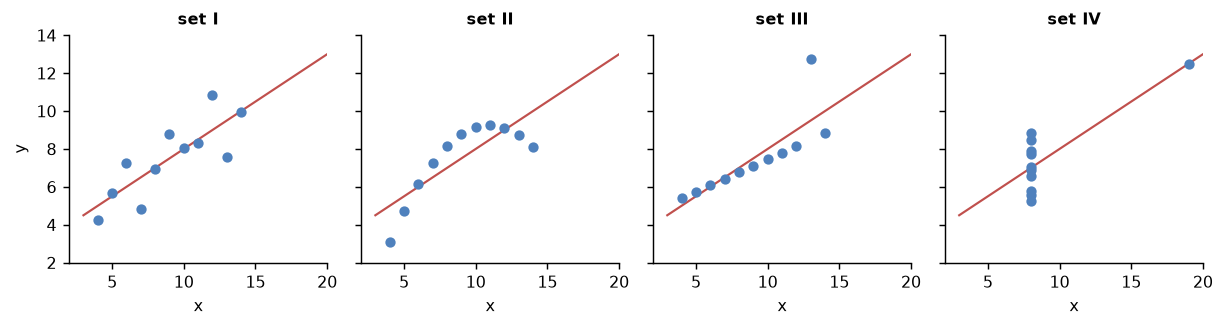

In [16]:
# Anscombe's quartet: the summary table, then the four plots.
ans_x = {1: [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5], 2: [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5],
         3: [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5], 4: [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8]}
ans_y = {1: [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68],
         2: [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74],
         3: [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73],
         4: [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]}
rows = []
for k in ans_x:
    xa, ya = np.array(ans_x[k], float), np.array(ans_y[k], float)
    lr = sstats.linregress(xa, ya)
    rows.append(dict(set=f"I II III IV".split()[k - 1], mean_x=xa.mean(), var_x=xa.var(ddof=1),
                     mean_y=ya.mean(), var_y=ya.var(ddof=1), corr=lr.rvalue,
                     slope=lr.slope, intercept=lr.intercept))
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("\nhand check of set I: mean_x = 99/11 = 9.00, var_x = 110/10 = 11.00, sd = %.4f" % np.sqrt(11))

fig, axes = plt.subplots(1, 4, figsize=(9.5, 2.6), sharex=True, sharey=True)
for ax, k, name in zip(axes, ans_x, ["I", "II", "III", "IV"]):
    xa, ya = np.array(ans_x[k], float), np.array(ans_y[k], float)
    lr = sstats.linregress(xa, ya)
    ax.scatter(xa, ya, s=22, color="#4f81bd", zorder=3)
    xs = np.linspace(3, 20, 10)
    ax.plot(xs, lr.intercept + lr.slope * xs, color="#c0504d", lw=1.2)
    ax.set_title(f"set {name}", fontsize=9); ax.set_xlabel("x")
axes[0].set_ylabel("y"); axes[0].set_xlim(2, 20); axes[0].set_ylim(2, 14)
plt.show()

<p class="caption"><b>Figure 12.</b> Anscombe's quartet. Every set has mean x = 9.00, variance of x = 11.00, mean y = 7.50, variance of y ≈ 4.13, correlation 0.82 and the regression line y = 3.00 + 0.50x — the red line is literally the same in all four panels. Set I is a plausible linear relation with scatter; set II is a perfect parabola; set III is a perfect line plus one outlier that drags the fit; set IV is a vertical stack plus a single leverage point that determines the slope entirely. Any of the four would be reported identically by a table of statistics.</p>

Matejka and Fitzmaurice turned Anscombe's hand construction into an algorithm: start from a cloud with the desired statistics, repeatedly nudge one point towards a target shape, and accept the nudge only if the summary statistics still round to the same two decimals.<sup class="c"><a href="#r10">[10]</a></sup> Simulated annealing lets the search escape local traps. Their famous output is a dinosaur; ours, generated here in a few seconds, is an X and a ring.

              mean x  mean y   sd x   sd y     r
random cloud   50.21   48.76  13.49  14.39 -0.06
X shape        50.21   48.76  13.49  14.39 -0.06
ring           50.21   48.76  13.49  14.39 -0.06
<cell 17>:47: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


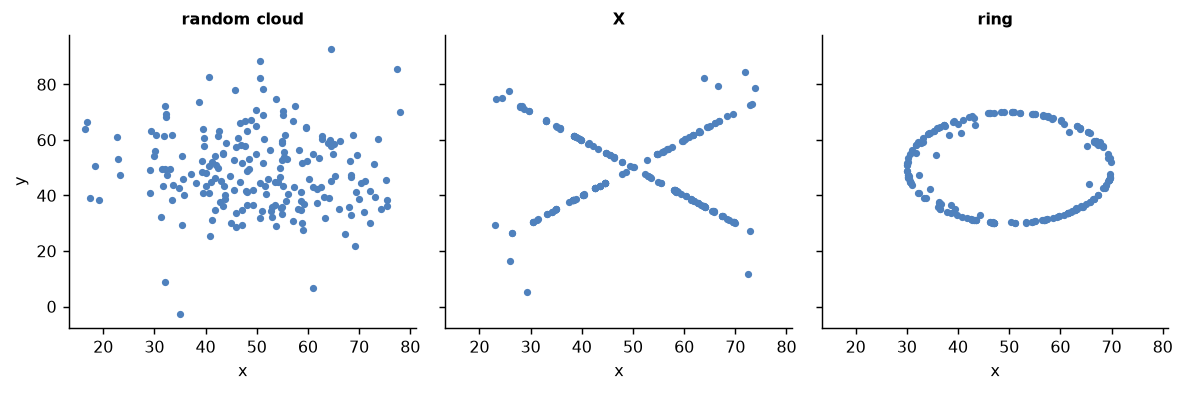

In [17]:
# A Datasaurus-style construction: morph a cloud into a shape while freezing its summary statistics.
def summary5(a):
    '''mean x, mean y, sd x, sd y, Pearson r -- the five numbers we freeze.'''
    return np.array([a[:, 0].mean(), a[:, 1].mean(), a[:, 0].std(ddof=1),
                     a[:, 1].std(ddof=1), np.corrcoef(a[:, 0], a[:, 1])[0, 1]])

def unchanged(a, b, dec=2):
    return np.all(np.round(a, dec) == np.round(b, dec))

def nearest(target, p):
    return np.min(np.hypot(target[:, 0] - p[0], target[:, 1] - p[1]))

def morph(start, target, iters=200_000, t0=0.4, t1=0.01, seed=3, step=0.8):
    '''Matejka-Fitzmaurice perturbation: move one point at a time towards the target shape,
    accept worse moves with an annealed probability, and reject anything that changes the
    summary statistics at two decimals.'''
    r = np.random.default_rng(seed)
    pts = start.copy(); frozen = summary5(pts); n = len(pts)
    for i in range(iters):
        temp = t0 + (t1 - t0) * i / iters
        j = int(r.integers(n)); old = pts[j].copy()
        pts[j] = old + r.normal(0, step, 2)
        if nearest(target, pts[j]) > nearest(target, old) and r.random() > np.exp(-1 / temp):
            pts[j] = old; continue
        if not unchanged(summary5(pts), frozen):
            pts[j] = old
    return pts

rng = np.random.default_rng(0)
cloud = np.c_[rng.normal(50, 14, 200), rng.normal(50, 14, 200)]
tr = np.random.default_rng(2)
u = tr.uniform(-1, 1, 200); sgn = np.where(tr.random(200) < .5, 1, -1)
shape_x = np.c_[50 + 24 * u, 50 + 24 * u * sgn]
ang = np.random.default_rng(1).uniform(0, 2 * np.pi, 200)
shape_o = np.c_[50 + 20 * np.cos(ang), 50 + 20 * np.sin(ang)]
out_x, out_o = morph(cloud, shape_x), morph(cloud, shape_o)

tab = pd.DataFrame([summary5(cloud), summary5(out_x), summary5(out_o)],
                   index=["random cloud", "X shape", "ring"],
                   columns=["mean x", "mean y", "sd x", "sd y", "r"])
print(tab.round(2).to_string())
fig, axes = plt.subplots(1, 3, figsize=(9.2, 3.1), sharex=True, sharey=True)
for ax, pts, ttl in zip(axes, [cloud, out_x, out_o], ["random cloud", "X", "ring"]):
    ax.scatter(pts[:, 0], pts[:, 1], s=9, color="#4f81bd")
    ax.set_title(ttl, fontsize=9); ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.show()

<p class="caption"><b>Figure 13.</b> Three datasets of 200 points with the same five summary statistics to two decimals — mean x 50.21, mean y 48.76, sd x 13.49, sd y 14.39, correlation −0.06 — and three completely different structures. The table above the figure is the proof; the figure is the point. A referee given only the table could not distinguish a featureless cloud from a ring with a hole in the middle. Run the EDA.</p>

## 9. Colour

Colour is the most-abused channel in scientific figures, and the three failures are well documented.<sup class="c"><a href="#r23">[23]</a></sup> **Non-uniform colour maps** such as the old `jet` create visual boundaries where the data are smooth and hide boundaries where the data jump, because the perceived lightness does not increase monotonically.<sup class="c"><a href="#r24">[24]</a></sup> **Non-accessible palettes** are unreadable to the ~4% of the population — about 8% of men of northern-European descent — with a colour-vision deficiency.<sup class="c"><a href="#r27">[27]</a></sup> **Colour used for nothing** adds ink without adding information.

The rules are short. For a continuous quantity use a perceptually uniform sequential map: `viridis`, `cividis`, `magma`. For a quantity with a meaningful zero use a diverging map centred on it. For categories use a qualitative palette designed for accessibility — the Okabe–Ito eight-colour set is the standard — and never more than about seven categories. And always encode the information twice: colour plus marker shape, or colour plus a direct label.<sup class="c"><a href="#r26">[26]</a></sup>

The cell below simulates how a figure looks to a reader with deuteranopia, using the physiologically derived transformation of Machado, Oliveira and Fernandes.<sup class="c"><a href="#r25">[25]</a></sup>

<cell 18>:42: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


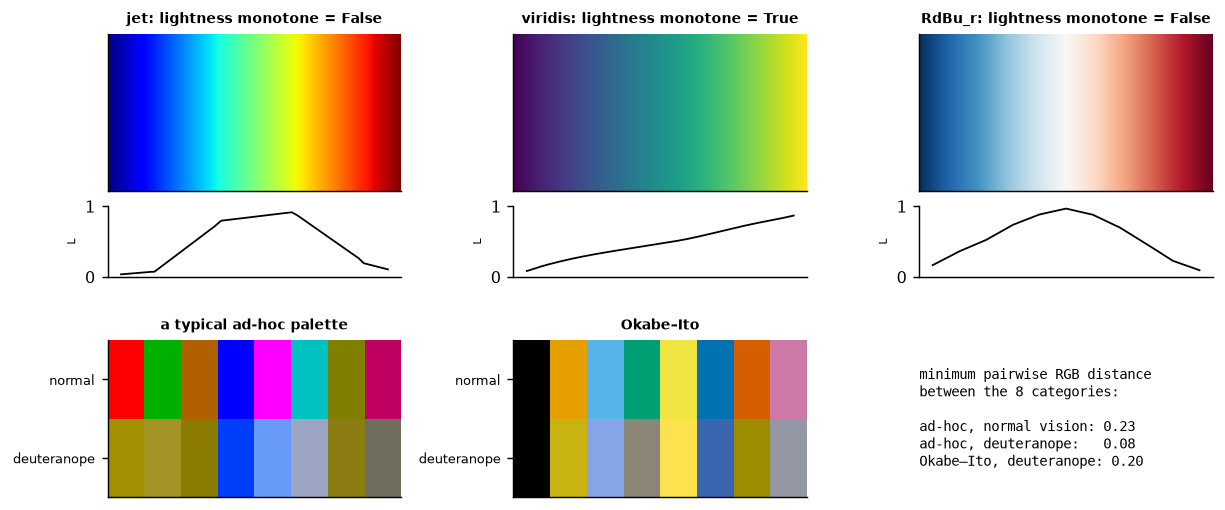

In [18]:
# Colour maps, a colour-blind-safe categorical palette, and a deuteranopia simulation.
# Machado, Oliveira & Fernandes (2009) deuteranomaly matrix at severity 1.0, applied in linear RGB.
M_DEUTAN = np.array([[0.367322, 0.860646, -0.227968],
                     [0.280085, 0.672501,  0.047413],
                     [-0.011820, 0.042940, 0.968881]])
def simulate_cvd(rgb):
    '''Approximate deuteranope appearance of an array of sRGB colours in [0, 1].'''
    lin = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    out = np.clip(lin @ M_DEUTAN.T, 0, 1)
    return np.where(out <= 0.0031308, out * 12.92, 1.055 * out ** (1 / 2.4) - 0.055)

OKABE_ITO = ["#000000", "#E69F00", "#56B4E9", "#009E73",
             "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]
bad_palette = ["#ff0000", "#00b000", "#b06000", "#0000ff", "#ff00ff", "#00c0c0", "#808000", "#c00060"]
grid = np.linspace(0, 1, 256).reshape(1, -1)

fig, axes = plt.subplots(2, 3, figsize=(9.5, 4.0))
for ax, cm in zip(axes[0], ["jet", "viridis", "RdBu_r"]):
    ax.imshow(grid, aspect="auto", cmap=cm)
    L = plt.get_cmap(cm)(np.linspace(0, 1, 256))[:, :3] @ [0.2126, 0.7152, 0.0722]
    ax.set_title(f"{cm}: lightness monotone = {bool(np.all(np.diff(L) > -1e-3))}", fontsize=8)
    ax.set_yticks([]); ax.set_xticks([])
    ax2 = ax.inset_axes([0, -0.55, 1, 0.45]); ax2.plot(L, color="k", lw=1)
    ax2.set_ylim(0, 1); ax2.set_xticks([]); ax2.set_yticks([0, 1]); ax2.set_ylabel("L", fontsize=6)
for ax, pal, ttl in [(axes[1][0], bad_palette, "a typical ad-hoc palette"),
                     (axes[1][1], OKABE_ITO, "Okabe–Ito")]:
    rgb = np.array([mpl.colors.to_rgb(c) for c in pal])
    ax.imshow(np.stack([rgb, simulate_cvd(rgb)]), aspect="auto")
    ax.set_yticks([0, 1]); ax.set_yticklabels(["normal", "deuteranope"], fontsize=7)
    ax.set_xticks([]); ax.set_title(ttl, fontsize=8)
rgbp = np.array([mpl.colors.to_rgb(c) for c in bad_palette])
dist_norm = np.min([np.linalg.norm(rgbp[i] - rgbp[j]) for i in range(8) for j in range(i + 1, 8)])
rgbd = simulate_cvd(rgbp)
dist_cvd = np.min([np.linalg.norm(rgbd[i] - rgbd[j]) for i in range(8) for j in range(i + 1, 8)])
rgbo = np.array([mpl.colors.to_rgb(c) for c in OKABE_ITO]); rgbod = simulate_cvd(rgbo)
dist_o = np.min([np.linalg.norm(rgbod[i] - rgbod[j]) for i in range(8) for j in range(i + 1, 8)])
axes[1][2].axis("off")
axes[1][2].text(0, .5, f"minimum pairwise RGB distance\nbetween the 8 categories:\n\n"
                       f"ad-hoc, normal vision: {dist_norm:.2f}\n"
                       f"ad-hoc, deuteranope:   {dist_cvd:.2f}\n"
                       f"Okabe–Ito, deuteranope: {dist_o:.2f}", fontsize=8, va="center", family="monospace")
plt.show()

<p class="caption"><b>Figure 14.</b> Top: three colour maps with their perceived-lightness profile beneath. <code>jet</code> is not monotone in lightness — it rises, falls and rises again — so equal steps in the data are not equal steps in appearance and spurious bands appear; <code>viridis</code> is monotone by construction; the diverging <code>RdBu_r</code> is deliberately non-monotone because its midpoint is meaningful. Bottom: eight categorical colours as seen normally and as seen by a deuteranope. In the ad-hoc palette the closest pair of categories collapses from an RGB distance of 0.23 to 0.08 — effectively indistinguishable — whereas the Okabe–Ito set keeps its closest pair at 0.20, barely changed from 0.26. Choosing the palette costs nothing; choosing it badly costs a reader.</p>

## 10. The anti-pattern gallery

Four errors appear in almost every seminar. Each is drawn here as it is usually drawn, then as it should be.

1. **The truncated axis.** A bar chart whose *y* axis does not start at zero exaggerates differences without stating that it does — bar length is the encoding, so truncating it lies. (A truncated axis on a *line* chart of a trend is legitimate and often necessary; the sin is specific to length-encoded geometry.)
2. **The dual axis.** Two series with different units on left and right axes. The apparent relation between them is entirely determined by the scaling the author chose, so the figure can be made to show correlation or anti-correlation at will.
3. **The rainbow map** (Section 9).
4. **The pie chart.** Humans compare angles poorly and lengths well,<sup class="c"><a href="#r11">[11]</a></sup> so a pie with more than three slices is harder to read than the bar chart of the same numbers.

<cell 19>:46: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
potency classes: {'weak (<5.5)': 1667, 'moderate': 1075, 'good': 961, 'potent (>7.5)': 577}
ratio largest/smallest class: 2.89 (the truncated chart makes it look like 15.2)


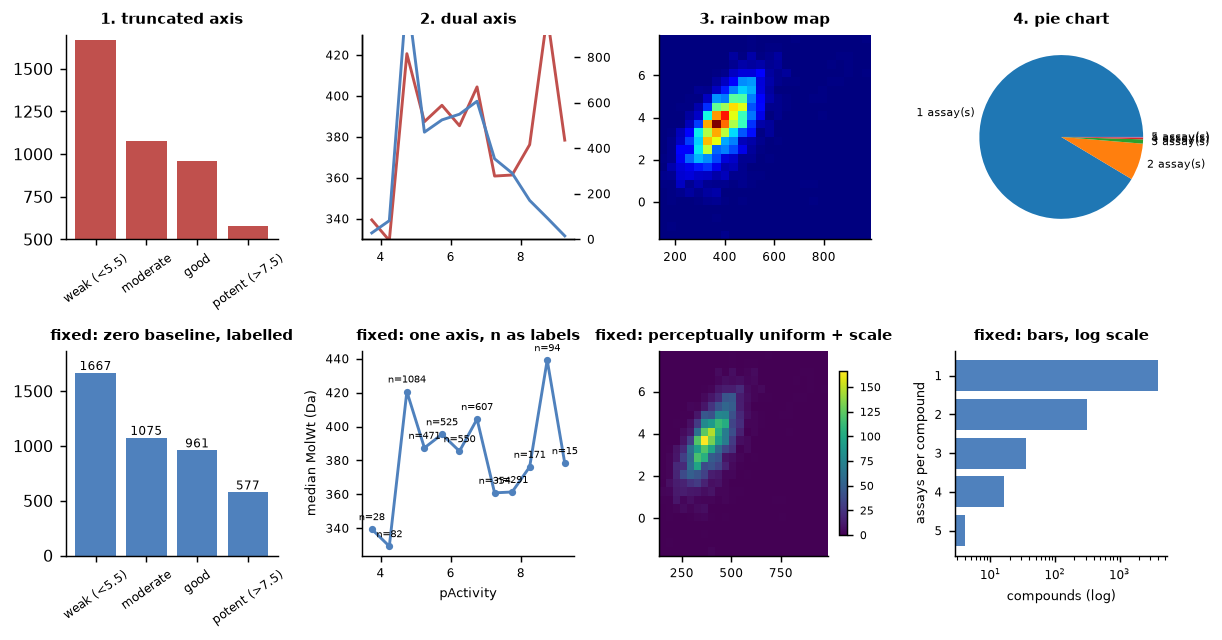

In [19]:
# The gallery: four charts drawn badly (top) and correctly (bottom), on real numbers from this table.
by_class = cmp.groupby("potency_class", observed=True).size()
assay_counts = cmp["n_assays"].value_counts().sort_index().head(5)
fig, axes = plt.subplots(2, 4, figsize=(9.5, 5.0))

axes[0][0].bar(by_class.index.astype(str), by_class.values, color="#c0504d")
axes[0][0].set_ylim(500, by_class.max() * 1.02)
axes[0][0].set_title("1. truncated axis", fontsize=8.5); axes[0][0].tick_params(axis="x", labelrotation=35, labelsize=6.5)
axes[1][0].bar(by_class.index.astype(str), by_class.values, color="#4f81bd")
axes[1][0].set_ylim(0, by_class.max() * 1.12)
for i, v in enumerate(by_class.values):
    axes[1][0].text(i, v + 25, str(v), ha="center", fontsize=6.5)
axes[1][0].set_title("fixed: zero baseline, labelled", fontsize=8.5)
axes[1][0].tick_params(axis="x", labelrotation=35, labelsize=6.5)

bins = np.arange(3.5, 10, .5)
med_mw = cmp.groupby(pd.cut(cmp["pActivity"], bins), observed=True)["MolWt"].median()
cnt = cmp.groupby(pd.cut(cmp["pActivity"], bins), observed=True).size()
ctr = (bins[:-1] + bins[1:]) / 2
ax = axes[0][1]; ax2 = ax.twinx()
ax.plot(ctr, med_mw.values, color="#c0504d", lw=1.6); ax2.plot(ctr, cnt.values, color="#4f81bd", lw=1.6)
ax.set_ylim(330, 430); ax2.set_ylim(0, 900); ax.set_title("2. dual axis", fontsize=8.5)
ax.tick_params(labelsize=6.5); ax2.tick_params(labelsize=6.5)
axes[1][1].plot(ctr, med_mw.values, color="#4f81bd", lw=1.6, marker="o", ms=3)
axes[1][1].set_ylabel("median MolWt (Da)", fontsize=7); axes[1][1].set_xlabel("pActivity", fontsize=7)
for xc, yc, nn in zip(ctr, med_mw.values, cnt.values):
    axes[1][1].annotate(f"n={nn}", (xc, yc), fontsize=5.4, xytext=(0, 5), textcoords="offset points", ha="center")
axes[1][1].set_title("fixed: one axis, n as labels", fontsize=8.5); axes[1][1].tick_params(labelsize=6.5)

H, xe, ye = np.histogram2d(cmp["MolWt"], cmp["MolLogP"], bins=24)
axes[0][2].imshow(H.T, origin="lower", cmap="jet", aspect="auto",
                  extent=[xe[0], xe[-1], ye[0], ye[-1]])
axes[0][2].set_title("3. rainbow map", fontsize=8.5); axes[0][2].tick_params(labelsize=6.5)
im = axes[1][2].imshow(H.T, origin="lower", cmap="viridis", aspect="auto",
                       extent=[xe[0], xe[-1], ye[0], ye[-1]])
fig.colorbar(im, ax=axes[1][2], shrink=.8).ax.tick_params(labelsize=6)
axes[1][2].set_title("fixed: perceptually uniform + scale", fontsize=8.5); axes[1][2].tick_params(labelsize=6.5)

axes[0][3].pie(assay_counts.values, labels=[f"{i} assay(s)" for i in assay_counts.index],
               textprops=dict(fontsize=6), colors=plt.get_cmap("tab10").colors)
axes[0][3].set_title("4. pie chart", fontsize=8.5)
axes[1][3].barh([f"{i}" for i in assay_counts.index][::-1], assay_counts.values[::-1], color="#4f81bd")
axes[1][3].set_xscale("log"); axes[1][3].set_xlabel("compounds (log)", fontsize=7)
axes[1][3].set_ylabel("assays per compound", fontsize=7)
axes[1][3].set_title("fixed: bars, log scale", fontsize=8.5); axes[1][3].tick_params(labelsize=6.5)
plt.show()
print("potency classes:", by_class.to_dict())
print("ratio largest/smallest class: %.2f (the truncated chart makes it look like %.1f)"
      % (by_class.max() / by_class.min(),
         (by_class.max() - 500) / (by_class.min() - 500)))

<p class="caption"><b>Figure 15.</b> Four anti-patterns and their repairs. (1) Truncating the bar axis at 500 makes the largest potency class look 15.2 times the smallest when the true ratio is 2.9. (2) The dual-axis panel invites the reader to see median molecular weight and compound count as "tracking each other"; the apparent agreement is produced by the two chosen *y* ranges and disappears when each series is plotted on its own axis. (3) The <code>jet</code> version of the same 2-D histogram invents a bright ridge where the data are smooth; <code>viridis</code> with a colour bar shows the single density peak that is actually there. (4) Five slices of a pie against five bars: the bars are ordered, labelled, and on a log scale that accommodates a 70-fold range the pie cannot show.</p>

<div class="exercise"><h4>Exercise 2</h4>
<p>Take the dual-axis panel and change only the right-hand <code>set_ylim</code> so that the two curves appear to be <em>anti</em>-correlated. You should be able to do it in one line. Then write the caption you would have to put under that figure for it to be honest — and notice that the honest caption makes the figure pointless.</p></div>

## 11. Three real anomalies

Checklist item 6. An anomaly is not a point to delete but a fact about the experiment that produced the data. We found three.

In [20]:
# Anomaly 1: pile-ups. Some pActivity values are shared by dozens of compounds.
counts = cmp["pActivity"].round(3).value_counts()
print("most frequent pActivity values and the concentration they correspond to:")
for v, k in counts.head(6).items():
    print(f"  pActivity {v:<7.3f} {k:>4d} compounds   = {10**(9-v):>10.1f} nM")
raw = load_data("rock1_chembl_raw.csv")
pile = cmp.loc[np.isclose(cmp["pActivity"], 6.26), "chembl_ids"].str.split("|").explode()
rows = raw[raw["molecule_chembl_id"].isin(set(pile)) & raw["standard_relation"].eq("=")]
print("\nthe 141 compounds at pActivity 6.26:")
print("  distinct standard_value:", rows["standard_value"].unique()[:4],
      "| assays:", rows["assay_chembl_id"].nunique(), "| documents:", rows["document_chembl_id"].nunique())
print("  largest contributing assay:", rows["assay_chembl_id"].value_counts().index[0],
      "with", int(rows["assay_chembl_id"].value_counts().iloc[0]), "of them")
print("  assay text:", rows["assay_description"].iloc[0][:110], "...")

most frequent pActivity values and the concentration they correspond to:
  pActivity 5.000    658 compounds   =    10000.0 nM
  pActivity 4.523    264 compounds   =    29991.6 nM
  pActivity 7.000    205 compounds   =      100.0 nM
  pActivity 6.000    161 compounds   =     1000.0 nM
  pActivity 6.260    141 compounds   =      549.5 nM
  pActivity 5.400    113 compounds   =     3981.1 nM

the 141 compounds at pActivity 6.26:
  distinct standard_value: [550.] | assays: 4 | documents: 4
  largest contributing assay: CHEMBL5733564 with 124 of them
  assay text: Inhibition of human GST-tagged catalytic ROCK1 expressed in baculovirus system using STK S2 peptide substrate  ...


**Anomaly 1 — reported-value pile-ups.** Five values account for an extraordinary share of the table. Two are censoring limits (658 compounds at exactly 5.000, i.e. "&gt; 10 µM", and 264 at 4.523, "&gt; 30 µM"); two are round numbers a chemist would write by hand (205 at exactly 7.000 = 100 nM, 161 at 6.000 = 1 µM); and one, 141 compounds at exactly 6.260, is an IC50 of exactly 550 nM. Identical potencies to three decimals for 141 distinct molecules do not occur by chance. Tracing them through `chembl_ids` back to the raw records shows they come from four assays in four documents, 124 of them from a single patent-derived assay that reported the same representative value for a whole compound series — a common practice in patent tables, where activities are quoted in bands rather than individually. For modelling this matters twice: those compounds carry far less information than their count suggests, and a random train/test split will put near-identical target values on both sides.

raw rows reported in uM: 470 | assays: 83 | documents: 77
their median reported value: 1.2 uM (= 1200 nM); overall median in nM-reporting rows: 550 nM

wide-spread compounds (max - min > 1 log unit): 60 of 337 with replicates
their range: median 1.46, max 3.30 log units
  pref_name  pActivity  pActivity_min  pActivity_max  n_measurements  n_documents
        NaN      6.950          5.300          8.600               2            1
GSK-269962A      8.770          5.523          8.796               6            5
    Y-27632      6.824          4.523          7.600              20           17
BELUMOSUDIL      5.131          4.620          7.620              19           14
<cell 21>:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


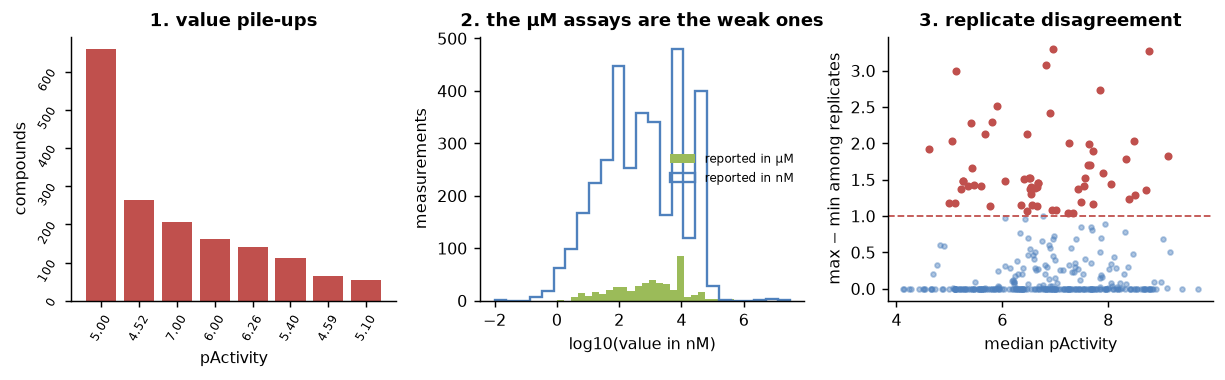

In [21]:
# Anomaly 2: assays that report in micromolar, and the censoring limits they imply.
um = raw[raw["units"].eq("uM")]
print("raw rows reported in uM:", len(um), "| assays:", um["assay_chembl_id"].nunique(),
      "| documents:", um["document_chembl_id"].nunique())
print("their median reported value: %.1f uM (= %.0f nM); overall median in nM-reporting rows: %.0f nM"
      % (um["value"].median(), 1000 * um["value"].median(),
         raw.loc[raw["units"].eq("nM"), "value"].median()))
# Anomaly 3: compounds whose replicates disagree by more than one log unit
ws = cmp[cmp["wide_spread"]]
print("\nwide-spread compounds (max - min > 1 log unit):", len(ws),
      "of", int((cmp['n_exact'] > 1).sum()), "with replicates")
print("their range: median %.2f, max %.2f log units" % (ws["pActivity_range"].median(), ws["pActivity_range"].max()))
print(ws.nlargest(4, "pActivity_range")[["pref_name", "pActivity", "pActivity_min", "pActivity_max",
                                         "n_measurements", "n_documents"]].to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.0))
axes[0].bar([f"{v:.2f}" for v in counts.head(8).index], counts.head(8).values, color="#c0504d")
axes[0].set_xlabel("pActivity"); axes[0].set_ylabel("compounds"); axes[0].tick_params(labelrotation=60, labelsize=6.5)
axes[0].set_title("1. value pile-ups")
axes[1].hist(np.log10(um["value"] * 1000), bins=25, color="#9bbb59", label="reported in µM")
axes[1].hist(np.log10(raw.loc[raw["units"].eq("nM"), "value"].clip(lower=1e-2)), bins=25,
             histtype="step", color="#4f81bd", lw=1.3, label="reported in nM")
axes[1].set_xlabel("log10(value in nM)"); axes[1].set_ylabel("measurements")
axes[1].legend(fontsize=6.8); axes[1].set_title("2. the µM assays are the weak ones")
rep = cmp.loc[cmp["n_exact"] > 1]
axes[2].scatter(rep["pActivity"], rep["pActivity_range"], s=7, alpha=.45, color="#4f81bd")
axes[2].scatter(ws["pActivity"], ws["pActivity_range"], s=12, color="#c0504d")
axes[2].axhline(1.0, color="#c0504d", ls="--", lw=1)
axes[2].set_xlabel("median pActivity"); axes[2].set_ylabel("max − min among replicates")
axes[2].set_title("3. replicate disagreement")
plt.show()

<p class="caption"><b>Figure 16.</b> The three anomalies. (1) The eight most frequent pActivity values, each shared by dozens of compounds. (2) Measurements reported in micromolar (filled) against those reported in nanomolar (outline), both converted to nanomolar: the 470 micromolar-reported rows, from 83 assays, sit visibly to the right of the nanomolar ones (medians 1,200 nM against 550 nM) but overlap them heavily — a tendency, not a separation. (3) Replicate disagreement against median potency: 60 compounds (red) disagree by more than one log unit, the worst by 3.3 — a thousandfold discrepancy between laboratories for the same molecule. Unit 6 turns this scatter into an estimate of the noise floor that caps any model's accuracy.</p>

**Anomaly 2 — the unit a paper uses carries information.** Four hundred and seventy raw measurements, from 83 assays in 77 documents, were reported in micromolar rather than nanomolar. Converted to a common unit their median is 1,200 nM against 550 nM for the nanomolar-reported rows — a factor of 2.2, with 52% of the micromolar rows above 1 µM against 40% of the nanomolar ones. The effect is modest and the two distributions overlap heavily, so this is a tendency rather than a clean separation: authors reach for micromolar when the compounds they are describing are weak. The unit is therefore not a neutral formatting choice but a weak proxy for the kind of experiment, and it is worth recording in the data card even though it would be wrong to treat it as a label.

**Anomaly 3 — replicate disagreement.** Sixty compounds have replicate measurements differing by more than one log unit, the extreme case by 3.3. These are not errors to delete: they are the dataset telling you how reproducible it is, and every one of them is an upper bound on how well a model can ever predict that compound.

In [22]:
# A fourth thing worth looking for: same-scaffold compounds with very different potencies.
big = d["scaffold_smiles"].value_counts().loc[lambda x: x >= 5].index
same = d[d["scaffold_smiles"].isin(big)]
rows = []
for sc, grp in same.groupby("scaffold_smiles", observed=True):
    v = grp["pActivity"].to_numpy()
    rows.append(dict(scaffold=sc[:34] + "…", n=len(grp), spread=v.max() - v.min(),
                     weakest=v.min(), strongest=v.max(),
                     mixed_types=bool((grp["n_Ki"] > 0).any() and (grp["n_IC50"] > 0).any())))
cl = pd.DataFrame(rows).sort_values("spread", ascending=False)
print("scaffold families with >= 5 measured compounds:", len(cl),
      "| spanning more than 2 log units:", int((cl['spread'] > 2).sum()))
print(cl.head(5).round(2).to_string(index=False))
print("\nof the wide families, those mixing Ki and IC50 measurements:",
      int(cl.loc[cl['spread'] > 2, 'mixed_types'].sum()))

scaffold families with >= 5 measured compounds: 94 | spanning more than 2 log units: 34
                           scaffold   n  spread  weakest  strongest  mixed_types
c1cncc(-c2c[nH]c3nccc(N4CCCCC4)c23…  10    4.53     4.30       8.82        False
O=C(NCc1ccccc1)c1ccc(-c2cn[nH]c2)c… 207    4.31     5.39       9.70        False
O=C(NCc1ccccc1)c1ccc(-c2ccncc2)cc1…  43    4.30     4.80       9.10         True
c1ncc(-c2c[nH]c3nccc(N4CCCCC4)c23)…  24    3.79     4.30       8.09        False
O=C(NCc1ccccc1)Nc1nc(-c2ccncc2)cs1…  59    3.76     4.28       8.05        False

of the wide families, those mixing Ki and IC50 measurements: 6


A fourth observation, offered as a hypothesis rather than a result. Compounds sharing a Bemis–Murcko scaffold are structural relatives, so a family spanning more than two log units contains at least one <strong>activity cliff</strong> — a small structural change with a large potency consequence.<sup class="c"><a href="#r33">[33]</a></sup><sup class="c"><a href="#r34">[34]</a></sup> Such compounds are the most informative in a series and the ones that break similarity-based models. They also have a mundane alternative explanation that has to be excluded first: several of these families mix Ki and IC50 measurements, and pooling those two quantities is itself a documented source of roughly half a log unit of noise.<sup class="c"><a href="#r30">[30]</a></sup> Telling a real cliff from a measurement artefact needs the structures themselves; the EDA's job is to find the candidates and label them as candidates.

## 12. Summary

- **EDA is a checklist**, not an inspiration: shape and grain, missingness, univariate distributions, pairwise relations, group comparisons, anomalies, write-up. Run it before any model.
- **The grammar of graphics** — data, aesthetics, geometry, statistic, scale, facet — turns "which chart?" into a set of explicit choices. seaborn expresses it directly; matplotlib's object API executes it exactly.
- **Every distribution display has a hidden parameter** except the ECDF: bin width for histograms (Scott 0.28, Freedman–Diaconis 0.22 log units here), bandwidth for KDEs, which also leak density past the data's boundary.
- **Box plots answer one question.** Two samples with matched quartiles had excess kurtosis +0.44 and −1.13 and entirely different shapes. Draw the points whenever the group is smaller than a few hundred.
- **Overplotting is a measurement problem.** At 4,280 points an opaque scatter shows only the silhouette; transparency, hexbin (busiest cell: 79 compounds) and subsampling each trade something, and the caption must say which.
- **Correlation matrices show redundancy, not causation.** <code>MolWt</code> and <code>HeavyAtoms</code> correlate at 0.979; no descriptor correlates with potency above 0.25.
- **Anscombe's quartet and the Datasaurus construction** are proofs, not anecdotes: three of our generated datasets share five summary statistics to two decimals and look nothing alike.
- **Colour is data encoding.** Perceptually uniform maps for quantities, Okabe–Ito for categories, and simulate a colour-vision deficiency before you publish — the ad-hoc palette's closest pair fell from an RGB distance of 0.23 to 0.08 under deuteranopia, while Okabe–Ito held at 0.20.
- **Three real anomalies** in this dataset: value pile-ups at censoring limits and round numbers, including 141 compounds reported at exactly 550 nM by four patent-derived assays; 470 measurements from 83 assays reported in micromolar, whose median is 2.2 times weaker than the nanomolar-reported ones; and 60 compounds whose replicates disagree by more than a log unit, the worst by 3.3.

<div class="box bridge"><h4>Bridge</h4>
<p><strong>Backwards:</strong> Unit 4 (<a href="../U4_Tidy_Data/index.html">Tidy data and pandas</a>) built the compound table explored here, and Unit 3 (<a href="../U3_Getting_Data/index.html">Getting data</a>) downloaded it. <strong>Forwards:</strong> Unit 6 (<a href="../U6_Data_Quality/index.html">Data quality, curation and bias</a>) turns the anomalies of Section 11 into quantitative bias diagnostics and a noise floor; Unit 7 (<a href="../U7_Estimation/index.html">Estimation</a>) attaches uncertainty to the summaries drawn here; Unit 20 (<a href="../U20_MD_Analytics/index.html">MD analytics</a>) applies the same EDA discipline to time series, where autocorrelation makes every plot in this unit misleading in a new way; and Unit 23 (<a href="../U23_Communication/index.html">Scientific communication</a>) takes these figures to publication quality. <strong>Sister courses:</strong> the chemical meaning of the descriptors plotted here is developed in <a href="../../../Cheminformatics/U5_Descriptors_Fingerprints/index.html">Unit 5</a> and the scaffold and chemical-space views in <a href="../../../Cheminformatics/U8_Chemical_Space/index.html">Unit 8</a> of the cheminformatics course; activity cliffs are the subject of its <a href="../../../Cheminformatics/U11_Similarity_SAR/index.html">Unit 11</a>; and the AI course covers the modelling that follows in <a href="../../../BGM411/Python/index.html">its own units</a>.</p></div>

## 13. Self-assessment

<details><summary>1. What is the one question EDA must answer before any model is fitted?</summary>
<p>What is actually in the table — its grain, its gaps, the shape of each variable and the relations between them — so that you know which modelling assumptions are already violated. The secondary purpose is to generate hypotheses; those must then be tested on data not used to find them.</p></details>

<details><summary>2. Name the layers of the grammar of graphics and map a hexbin plot onto them.</summary>
<p>Data, aesthetic mapping, geometry, statistical transformation, scales, facets, coordinates/theme. A hexbin is: data = the compound table; aesthetics x = MolWt, y = MolLogP, fill = count; geometry = hexagon; statistic = count of points per hexagonal bin; scales = linear axes and a sequential colour map; no facets.</p></details>

<details><summary>3. Why is the ECDF the only distribution display with no tuning parameter, and why is it still not the default?</summary>
<p>Because it plots the data themselves: for each observed value, the fraction of observations at or below it. Nothing is binned or smoothed. It is not the default because most readers cannot see a mode in it — the eye reads density far better from a histogram than slope from a cumulative curve.</p></details>

<details><summary>4. Your KDE shows density below the smallest observed value. What happened and what do you do?</summary>
<p>The kernel is symmetric and spills past the boundary, assigning density to impossible values. Either state the boundary explicitly and truncate, use a boundary-corrected or reflected kernel, or show an ECDF or histogram instead. Never present the spill as if it were data.</p></details>

<details><summary>5. A referee asks you to replace your strip plot of six groups with box plots. When should you refuse?</summary>
<p>When the groups are small or unequal, or when any distribution is multimodal or truncated. In Figure 6 family S6 has 16 compounds and S2 is a wall of 23 points against a ceiling at 5.10 — a box plot shows neither. Offer a box overlaid with the points, which satisfies both of you.</p></details>

<details><summary>6. Two descriptors correlate at 0.98. What does that mean for an EDA report and for a model?</summary>
<p>They carry one piece of information between them. In the report, say so and show one. In a model, the pair makes a linear fit's coefficients unstable and uninterpretable (collinearity), though it rarely hurts a tree ensemble's predictions; feature selection or a dimensionality reduction (Unit 13) is the standard response.</p></details>

<details><summary>7. What exactly does Anscombe's quartet prove?</summary>
<p>That mean, variance, correlation and the least-squares line are compatible with structurally different data — a linear relation with noise, a parabola, a line plus an outlier, and a vertical stack plus one leverage point. Numerical summaries are necessary and never sufficient; the plot is part of the analysis, not the presentation.</p></details>

<details><summary>8. Why is a truncated y axis dishonest on a bar chart but acceptable on a line chart?</summary>
<p>Because a bar encodes the value as a <em>length</em> measured from the baseline, so moving the baseline changes the encoded quantity; truncating made our largest class look 4.0 times the smallest instead of 2.9. A line encodes value as position, and the reader reads changes rather than lengths, so a restricted range is a legitimate zoom — provided the axis is labelled.</p></details>

<details><summary>9. Why is <code>jet</code> a bad colour map and <code>viridis</code> a good one?</summary>
<p>Perceived lightness along <code>jet</code> rises, falls and rises again, so equal data steps are not equal perceptual steps: false boundaries appear at the yellow and cyan bands and real contrast is lost in the green. <code>viridis</code> is constructed to increase monotonically in lightness and to remain distinguishable under the common colour-vision deficiencies, so it also survives greyscale printing.</p></details>

<details><summary>10. You find 141 compounds with exactly the same reported potency. What do you do?</summary>
<p>Trace them to their source records before anything else — here, patent-derived assays reporting a single representative value for many compounds. Then record the finding in the data card, treat those compounds as carrying far less information than their count suggests, and make sure the train/test split does not place near-duplicates of the same value on both sides.</p></details>

<details><summary>11. Why is "measurements reported in µM are the weak ones" a problem rather than a curiosity?</summary>
<p>Because the unit becomes a weak proxy for the experiment type: the micromolar-reported rows are 2.2 times weaker on median than the nanomolar ones. The shift is modest and the distributions overlap, so it is not a label to split on, but it means the reported unit is correlated with the answer — something to record in the data card and to check before treating the pooled set as homogeneous.</p></details>

<details><summary>12. How many of the plots in this unit would you put in a paper, and what changes first?</summary>
<p>Very few, and that is the point: EDA figures are for you. For publication the changes are a single clear message per figure, axis labels with units, a colour-blind-safe palette, the sample size stated in the panel or caption, and the caption reporting the numbers the reader is meant to take away. Unit 23 does this systematically.</p></details>

## Glossary

<dl class="gloss">
<dt>Aesthetic mapping</dt><dd>The assignment of data columns to visual channels — position, colour, size, shape, transparency.</dd>
<dt>Anti-pattern</dt><dd>A chart convention that reliably misleads: truncated bar axis, dual axis, rainbow colour map, pie with many slices.</dd>
<dt>Bandwidth</dt><dd>The width of the kernel in a density estimate; the KDE's equivalent of bin width, and its hidden parameter.</dd>
<dt>Bemis–Murcko scaffold</dt><dd>A molecule reduced to its ring systems and the linkers between them; the standard way of grouping compounds into chemical families.</dd>
<dt>Clustermap</dt><dd>A heatmap whose rows and columns are reordered by hierarchical clustering so that correlated blocks become contiguous.</dd>
<dt>Deuteranopia</dt><dd>The commonest colour-vision deficiency, a reduced ability to distinguish red from green; simulated here with the Machado model.</dd>
<dt>ECDF</dt><dd>Empirical cumulative distribution function: for each value, the fraction of observations at or below it. No tuning parameter.</dd>
<dt>Exploratory data analysis</dt><dd>Examining data to find structure and generate hypotheses, as distinct from confirmatory analysis, which tests a hypothesis formed beforehand.</dd>
<dt>Grammar of graphics</dt><dd>The decomposition of a statistical graphic into data, aesthetics, geometry, statistical transformation, scales, facets and coordinates.</dd>
<dt>Overplotting</dt><dd>So many marks that the ink saturates and density becomes unreadable; treated with transparency, binning or subsampling.</dd>
<dt>Pile-up</dt><dd>A value shared by far more records than chance allows, usually a reporting convention rather than a measurement.</dd>
<dt>Small multiples</dt><dd>One small plot repeated across the levels of a variable with shared axes, so the panels are directly comparable.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Wickham H. A layered grammar of graphics. <i>Journal of Computational and Graphical Statistics</i> 2010;19(1):3–28. doi:<a href="https://doi.org/10.1198/jcgs.2009.07098">10.1198/jcgs.2009.07098</a></li>
<li id="r2">Hunter JD. Matplotlib: a 2D graphics environment. <i>Computing in Science &amp; Engineering</i> 2007;9(3):90–95. doi:<a href="https://doi.org/10.1109/MCSE.2007.55">10.1109/MCSE.2007.55</a></li>
<li id="r3">Waskom ML. seaborn: statistical data visualization. <i>Journal of Open Source Software</i> 2021;6(60):3021. doi:<a href="https://doi.org/10.21105/joss.03021">10.21105/joss.03021</a></li>
<li id="r4">Harris CR, Millman KJ, van der Walt SJ, <i>et al.</i> Array programming with NumPy. <i>Nature</i> 2020;585:357–362. doi:<a href="https://doi.org/10.1038/s41586-020-2649-2">10.1038/s41586-020-2649-2</a></li>
<li id="r5">Virtanen P, Gommers R, Oliphant TE, <i>et al.</i> SciPy 1.0: fundamental algorithms for scientific computing in Python. <i>Nature Methods</i> 2020;17:261–272. doi:<a href="https://doi.org/10.1038/s41592-019-0686-2">10.1038/s41592-019-0686-2</a></li>
<li id="r6">McKinney W. Data structures for statistical computing in Python. <i>Proceedings of the 9th Python in Science Conference</i> 2010:56–61. doi:<a href="https://doi.org/10.25080/Majora-92bf1922-00a">10.25080/Majora-92bf1922-00a</a></li>
<li id="r7">Wickham H. Tidy data. <i>Journal of Statistical Software</i> 2014;59(10):1–23. doi:<a href="https://doi.org/10.18637/jss.v059.i10">10.18637/jss.v059.i10</a></li>
<li id="r8">Rougier NP, Droettboom M, Bourne PE. Ten simple rules for better figures. <i>PLoS Computational Biology</i> 2014;10(9):e1003833. doi:<a href="https://doi.org/10.1371/journal.pcbi.1003833">10.1371/journal.pcbi.1003833</a></li>
<li id="r9">Anscombe FJ. Graphs in statistical analysis. <i>The American Statistician</i> 1973;27(1):17–21. doi:<a href="https://doi.org/10.1080/00031305.1973.10478966">10.1080/00031305.1973.10478966</a></li>
<li id="r10">Matejka J, Fitzmaurice G. Same stats, different graphs: generating datasets with varied appearance and identical statistics through simulated annealing. <i>Proceedings of the 2017 CHI Conference on Human Factors in Computing Systems</i> 2017:1290–1294. doi:<a href="https://doi.org/10.1145/3025453.3025912">10.1145/3025453.3025912</a></li>
<li id="r11">Cleveland WS, McGill R. Graphical perception: theory, experimentation, and application to the development of graphical methods. <i>Journal of the American Statistical Association</i> 1984;79(387):531–554. doi:<a href="https://doi.org/10.1080/01621459.1984.10478080">10.1080/01621459.1984.10478080</a></li>
<li id="r12">Scott DW. On optimal and data-based histograms. <i>Biometrika</i> 1979;66(3):605–610. doi:<a href="https://doi.org/10.1093/biomet/66.3.605">10.1093/biomet/66.3.605</a></li>
<li id="r13">Freedman D, Diaconis P. On the histogram as a density estimator: L2 theory. <i>Zeitschrift für Wahrscheinlichkeitstheorie und verwandte Gebiete</i> 1981;57(4):453–476. doi:<a href="https://doi.org/10.1007/BF01025868">10.1007/BF01025868</a></li>
<li id="r14">Wand MP. Data-based choice of histogram bin width. <i>The American Statistician</i> 1997;51(1):59–64. doi:<a href="https://doi.org/10.1080/00031305.1997.10473591">10.1080/00031305.1997.10473591</a></li>
<li id="r15">Hintze JL, Nelson RD. Violin plots: a box plot–density trace synergism. <i>The American Statistician</i> 1998;52(2):181–184. doi:<a href="https://doi.org/10.1080/00031305.1998.10480559">10.1080/00031305.1998.10480559</a></li>
<li id="r16">McGill R, Tukey JW, Larsen WA. Variations of box plots. <i>The American Statistician</i> 1978;32(1):12–16. doi:<a href="https://doi.org/10.1080/00031305.1978.10479236">10.1080/00031305.1978.10479236</a></li>
<li id="r17">Krzywinski M, Altman N. Visualizing samples with box plots. <i>Nature Methods</i> 2014;11:119–120. doi:<a href="https://doi.org/10.1038/nmeth.2813">10.1038/nmeth.2813</a></li>
<li id="r18">Streit M, Gehlenborg N. Bar charts and box plots. <i>Nature Methods</i> 2014;11:117. doi:<a href="https://doi.org/10.1038/nmeth.2807">10.1038/nmeth.2807</a></li>
<li id="r19">Weissgerber TL, Milic NM, Winham SJ, Garovic VD. Beyond bar and line graphs: time for a new data presentation paradigm. <i>PLoS Biology</i> 2015;13(4):e1002128. doi:<a href="https://doi.org/10.1371/journal.pbio.1002128">10.1371/journal.pbio.1002128</a></li>
<li id="r20">Weissgerber TL, Winham SJ, Heinzen EP, <i>et al.</i> Reveal, don't conceal: transforming data visualization to improve transparency. <i>Circulation</i> 2019;140(18):1506–1518. doi:<a href="https://doi.org/10.1161/CIRCULATIONAHA.118.037777">10.1161/CIRCULATIONAHA.118.037777</a></li>
<li id="r21">Allen M, Poggiali D, Whitaker K, Marshall TR, van Langen J, Kievit RA. Raincloud plots: a multi-platform tool for robust data visualization. <i>Wellcome Open Research</i> 2021;4:63. doi:<a href="https://doi.org/10.12688/wellcomeopenres.15191.2">10.12688/wellcomeopenres.15191.2</a></li>
<li id="r22">Hartigan JA, Hartigan PM. The dip test of unimodality. <i>The Annals of Statistics</i> 1985;13(1):70–84. doi:<a href="https://doi.org/10.1214/aos/1176346577">10.1214/aos/1176346577</a></li>
<li id="r23">Crameri F, Shephard GE, Heron PJ. The misuse of colour in science communication. <i>Nature Communications</i> 2020;11:5444. doi:<a href="https://doi.org/10.1038/s41467-020-19160-7">10.1038/s41467-020-19160-7</a></li>
<li id="r24">Borland D, Taylor RM. Rainbow color map (still) considered harmful. <i>IEEE Computer Graphics and Applications</i> 2007;27(2):14–17. doi:<a href="https://doi.org/10.1109/MCG.2007.323435">10.1109/MCG.2007.323435</a></li>
<li id="r25">Machado GM, Oliveira MM, Fernandes LAF. A physiologically-based model for simulation of color vision deficiency. <i>IEEE Transactions on Visualization and Computer Graphics</i> 2009;15(6):1291–1298. doi:<a href="https://doi.org/10.1109/TVCG.2009.113">10.1109/TVCG.2009.113</a></li>
<li id="r26">Harrower M, Brewer CA. ColorBrewer.org: an online tool for selecting colour schemes for maps. <i>The Cartographic Journal</i> 2003;40(1):27–37. doi:<a href="https://doi.org/10.1179/000870403235002042">10.1179/000870403235002042</a></li>
<li id="r27">Nuñez JR, Anderton CR, Renslow RS. Optimizing colormaps with consideration for color vision deficiency to enable accurate interpretation of scientific data. <i>PLoS ONE</i> 2018;13(7):e0199239. doi:<a href="https://doi.org/10.1371/journal.pone.0199239">10.1371/journal.pone.0199239</a></li>
<li id="r28">Gelman A, Unwin A. Infovis and statistical graphics: different goals, different looks. <i>Journal of Computational and Graphical Statistics</i> 2013;22(1):2–28. doi:<a href="https://doi.org/10.1080/10618600.2012.761137">10.1080/10618600.2012.761137</a></li>
<li id="r29">Zdrazil B, Felix E, Hunter F, <i>et al.</i> The ChEMBL Database in 2023. <i>Nucleic Acids Research</i> 2024;52(D1):D1180–D1192. doi:<a href="https://doi.org/10.1093/nar/gkad1004">10.1093/nar/gkad1004</a></li>
<li id="r30">Kalliokoski T, Kramer C, Vulpetti A, Gedeck P. Comparability of mixed IC50 data — a statistical analysis. <i>PLoS ONE</i> 2013;8(4):e61007. doi:<a href="https://doi.org/10.1371/journal.pone.0061007">10.1371/journal.pone.0061007</a></li>
<li id="r31">Lipinski CA, Lombardo F, Dominy BW, Feeney PJ. Experimental and computational approaches to estimate solubility and permeability in drug discovery and development settings. <i>Advanced Drug Delivery Reviews</i> 2001;46(1–3):3–26. doi:<a href="https://doi.org/10.1016/S0169-409X(00)00129-0">10.1016/S0169-409X(00)00129-0</a></li>
<li id="r32">Bickerton GR, Paolini GV, Besnard J, Muresan S, Hopkins AL. Quantifying the chemical beauty of drugs. <i>Nature Chemistry</i> 2012;4:90–98. doi:<a href="https://doi.org/10.1038/nchem.1243">10.1038/nchem.1243</a></li>
<li id="r33">Maggiora GM. On outliers and activity cliffs — why QSAR often disappoints. <i>Journal of Chemical Information and Modeling</i> 2006;46(4):1535. doi:<a href="https://doi.org/10.1021/ci060117s">10.1021/ci060117s</a></li>
<li id="r34">Stumpfe D, Bajorath J. Exploring activity cliffs in medicinal chemistry. <i>Journal of Medicinal Chemistry</i> 2012;55(7):2932–2942. doi:<a href="https://doi.org/10.1021/jm201706b">10.1021/jm201706b</a></li>
<li id="r35">Bemis GW, Murcko MA. The properties of known drugs. 1. Molecular frameworks. <i>Journal of Medicinal Chemistry</i> 1996;39(15):2887–2893. doi:<a href="https://doi.org/10.1021/jm9602928">10.1021/jm9602928</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Tukey JW. <i>Exploratory Data Analysis</i>. Addison-Wesley, 1977 — the book that named the subject.</li>
<li>Wilkinson L. <i>The Grammar of Graphics</i>, 2nd ed. Springer, 2005 — the formal source of Section 2.</li>
<li>Wilke CO. <i>Fundamentals of Data Visualization</i>. O'Reilly, 2019 — free online; the most practical modern guide.</li>
<li>Healy K. <i>Data Visualization: A Practical Introduction</i>. Princeton University Press, 2018 — free online.</li>
<li>VanderPlas J. <i>Python Data Science Handbook</i>, 2nd ed. O'Reilly, 2022 — chapter 4 on matplotlib; free online.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>seaborn tutorial, "Overview of plotting functions" — figure-level versus axes-level functions.</li>
<li>matplotlib, "The lifecycle of a plot" and the cheat sheets.</li>
<li>Scientific colour maps (Crameri) and the Okabe–Ito palette definition.</li>
<li>From Data to Viz (data-to-viz.com) — a decision tree from data shape to chart type, with the caveats of each.</li>
</ul>